### Instructions before running the notebook

In order to run this document, you will need to have argosim installed. This can be done using:

pip install argosim

Alternatively, you can follow the instructions in the argosim github repository: https://github.com/ARGOS-telescope/argosim

In [1]:
import os
import glob

import matplotlib.pyplot as plt
from matplotlib import cm, colors

import numpy as np

import astropy.units as u
from astropy.table import QTable
import astropy.constants as constants
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, Galactic
from astropy.time import Time

import healpy as hp

import scipy
import scipy.special

import argosim
from argosim import antenna_utils, plot_utils, beam_utils, imaging_utils

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from PIL import Image


<font size="5">
Setup ARGOSIM
<font>

In [2]:
#Constants
frequency = 1.42e9*u.hertz 
samp_rate = 1e7*(1/u.second)
bins = 1024
num_chan = int(32e3)

diam_ant = 0.18

n_antenna = 9
n_antenna_E = 3
n_antenna_N = 3

radius_antenna_grid = 2

lat = 52.16 / 180 * np.pi
lat_deg = 52.16
dec = 35.0 / 180 * np.pi
dec_deg = 35.0

npix = 256

In [3]:
#Definitions
def uv_tracks(baselines, track_time=1/3, t_0=0, n_times=5, f=frequency, df=10e6, n_freqs=num_chan, lat=lat_deg,dec=lat_deg):
    """ Calculate the uv tracks made by an array configuration.
    Default values from single cantenna experiment.
    
    baselines :     baselines for the array configuration (list)
    track_time :    observation duration in hours (float)
    t_0 :           start time in hours ()
    n_times :       how many observations (int)
    f :             frequency of observation (Hz)
    df :            frequency range (Hz) 
    n_frequs :      number of frequency samples (number of channels) (int)
    lat :           latitude (deg), default Leiden (NL)
    """

    lat = lat * np.pi / 180 # in radians
    dec = lat # assuming it's at the zenith  # TODO
    
    uv_track, _ = antenna_utils.uv_track_multiband(baselines, lat=lat, dec=dec, track_time=track_time, t_0=t_0, 
                                                    n_times=n_times, f=f, df=df, n_freqs=int(n_freqs), multi_band=False)

    uv_array = uv_track
    return uv_array


def laptop_dist(ant_array, laptop_pos, max_dist=10.):
    """ Calculate distance between array points and one laptop. (curvy gound not taken into account bc meh) 

    ant_array  : positions of antennas [x,y,z]
    laptop_pos : position of laptop [x,y,z]
    max_dist   : maximum allowed distance between laptop and antenna (meters) (float)
    makefig    : make figure of the situation (plot_laptop_dist function)
    """ 
    distances, too_far = [], []
    for i in range(len(ant_array)):
        x_ant, y_ant, z_ant = ant_array[i,0], ant_array[i,1], ant_array[i,2]
        distance = np.sqrt(np.abs(x_ant-laptop_pos[0])**2 + np.abs(y_ant-laptop_pos[1])**2 + np.abs(z_ant-laptop_pos[2])**2)
        if distance >= max_dist:
            print(f'Max allowed distance exceeded: {np.round(distance, 3)} m between laptop and antenna at {ant_array[i]}.') 
            too_far.append(i)
        distances.append(distance)
        
    return distances, too_far
    
# Functions that plot things

def plot_config(positions, color=None, title='Antenna array', savefig=False):
    """ plot antenna configuration in x,y plane
    positions: list of [x,y,z]
    """ 
    fig, axs = plt.subplots(1,1, figsize=(5,5))
    axs.plot(positions[:,0], positions[:,1], '.', color=color)
    axs.set_title(title)
    axs.set_xlabel('x (East) [m]') 
    axs.set_ylabel('y (North) [m]')
    axs.grid()
    if savefig:
        plt.savefig('./figures/antenna_array.pdf')
    plt.show()
    return


def plot_uv(uv_track, color=None, title='uv tracks', savefig=False):
    """ plot uv coverage
    uv_track : as calculated by uv_tracks
    """
    fig, axs = plt.subplots(1,1, figsize=(5,5))
    axs.plot(uv_track[:,0], uv_track[:,1], '.', color=color)
    axs.set_xlabel('u')
    axs.set_ylabel('v')
    axs.set_title(title)
    axs.grid(alpha=.5)
    if savefig:
        plt.savefig('./figures/uv-tracks.pdf')
    plt.show()
    return


def plot_laptop_dist(ant_array, laptop_pos, max_dist, distances=None, suppress_gray=False, offset=0., savefig=False):
    """ Plot the array situation and laptop position. If distances is not given, it will be calculated here.
    
    ant_array :  array with antenna positions [x,y,z]
    laptop_pos : laptop position [x,y,z]
    max_dist :   max distance between laptop and antenna
    distances :  calculated distances between antenna and laptop

    Plot options:
    suppress_gray : suppress gray lines
    offset :        offset for the distance labels in the plot
    savefig :       save figure
    """
    if distances==None:
        distances, too_far = laptop_dist(ant_array, laptop_pos, max_dist)
        
    fig, axs = plt.subplots(1,1, figsize=(6,6))
    
    # Draw lines between laptop and antennas
    for i in range(len(ant_array)):
        if i in too_far:
            axs.plot([ant_array[:,0][i],laptop_pos[0]], [ant_array[:,1][i],laptop_pos[1]], alpha=.4, color='red')
            axs.annotate(f'{np.round(distances[i],2)} m', xy=(ant_array[:,0][i]+offset, ant_array[:,1][i]+offset), size=10, color='maroon')
        else:
            if suppress_gray:
                pass
            else:
                axs.plot([ant_array[:,0][i],laptop_pos[0]], [ant_array[:,1][i],laptop_pos[1]], alpha=.4, color='gray')
                axs.annotate(f'{np.round(distances[i],2)} m', xy=(ant_array[:,0][i]+offset, ant_array[:,1][i]+offset), size=10)
        
    # Draw laptop and antenna points
    axs.plot(ant_array[:,0], ant_array[:,1], '.', color='black', markersize=8, label='antennas')
    axs.plot(laptop_pos[0], laptop_pos[1], color='fuchsia', marker='*', markersize=8, label='laptop')
        
    axs.set_title('Antenna configuration with laptop')
    axs.set_xlabel('x (East) [m]') 
    axs.set_ylabel('y (North) [m]')
    axs.grid(alpha=.5)
    axs.legend(handles=[Line2D([0],[0], marker='o', linewidth=0, markersize=8, color='black', label='antenna'),
                 Line2D([0],[0], marker='*', linewidth=0, markersize=8, color='fuchsia', label='laptop')])

    if savefig:
        plt.savefig('./figures/antenna_laptop_config.pdf')
    plt.show()

    return

def compute_max_baseline(array):
    separations = np.array([array[i]-array[j] for i in range(len(array)) for j in range(len(array))])
    separations = np.linalg.norm(separations, axis=1)
    max_separation = np.max(separations)
    max_separation_indices = np.unravel_index(np.argmax(separations), (len(array), len(array)))
    # add one to match antenna indices starting from 1
    max_separation_indices = (max_separation_indices[0] + 1, max_separation_indices[1] + 1)

    return max_separation, max_separation_indices

Max baseline for circular array: 3.9392310120488325
Max baseline for Y array: 3.4641016151377553
Max baseline for uniform array: 2.8284271247461903
Max baseline for random array: 2.0266906337012225
Max baseline for circular-Y array: 4.0


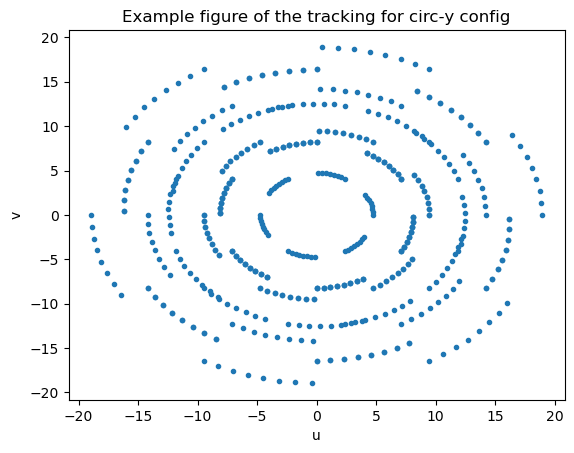

In [4]:
#Standard array examples:
circle_array  = antenna_utils.circular_antenna_arr(n_antenna=n_antenna, r=radius_antenna_grid)
Y_array       = antenna_utils.y_antenna_arr(n_antenna=n_antenna, r=radius_antenna_grid)  # n is per arm
uniform_array = antenna_utils.uni_antenna_array(n_antenna_E=n_antenna_E, n_antenna_N=n_antenna_N, E_lim=radius_antenna_grid, N_lim=radius_antenna_grid, U_lim=0.0)
random_array  = antenna_utils.random_antenna_arr(n_antenna=n_antenna, E_lim=radius_antenna_grid, N_lim=radius_antenna_grid)
circ_y_array  = antenna_utils.combine_antenna_arr(antenna_utils.circular_antenna_arr(n_antenna=n_antenna-3, r=radius_antenna_grid),
                                                  antenna_utils.y_antenna_arr(n_antenna=1, r=1))

# Baselines
b_circ    = antenna_utils.get_baselines(circle_array)
b_Y       = antenna_utils.get_baselines(Y_array)
b_uniform = antenna_utils.get_baselines(uniform_array)
b_random  = antenna_utils.get_baselines(random_array)
b_circ_y  = antenna_utils.get_baselines(circ_y_array)

max_b_circ, max_b_circ_indices = compute_max_baseline(circle_array)
max_b_Y, max_b_Y_indices = compute_max_baseline(Y_array)
max_b_uniform, max_b_uniform_indices = compute_max_baseline(uniform_array)
max_b_random, max_b_random_indices = compute_max_baseline(random_array)
max_b_circ_y, max_b_circ_y_indices = compute_max_baseline(circ_y_array)

print('Max baseline for circular array:', max_b_circ)
print('Max baseline for Y array:', max_b_Y)
print('Max baseline for uniform array:', max_b_uniform)
print('Max baseline for random array:', max_b_random)
print('Max baseline for circular-Y array:', max_b_circ_y)

#tracking
track_time = 2.0 #h
n_times=8 #8 measurements in 2h

uv_circ    = antenna_utils.uv_track_multiband(b_circ, lat=lat, dec=dec, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_Y       = antenna_utils.uv_track_multiband(b_Y, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_uniform = antenna_utils.uv_track_multiband(b_uniform, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_random  = antenna_utils.uv_track_multiband(b_random, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)
uv_circ_y  = antenna_utils.uv_track_multiband(b_circ_y, lat=lat_deg, dec=lat_deg, 
                                              track_time=track_time, n_times=n_times,f=frequency)

#example figure of the tracking for circ-y config:
plt.figure()
plt.plot(uv_circ_y[0][:,0], uv_circ_y[0][:,1],'.')
plt.title('Example figure of the tracking for circ-y config')
plt.xlabel('u')
plt.ylabel('v')
plt.show()


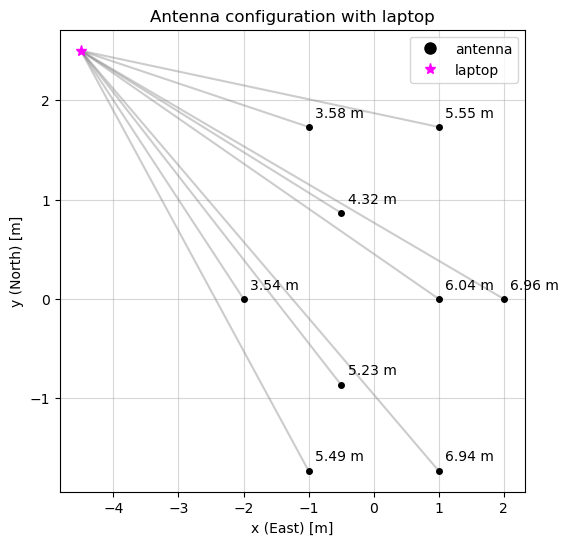

In [5]:
#calculating laptop distance
laptop_pos = [-4.5, 2.5, 0] #relative to the (0,0,0) of the array

plot_laptop_dist(circ_y_array, laptop_pos=laptop_pos, max_dist=10., offset=.1, savefig=False)


In [6]:
#Airy beam class, instead of standard argosim CosCube

def airy_beam_fn(first_null_radius):
    """
    Returns the Airy power pattern of a circular aperture.

    Parameters
    ----------
    first_null_radius : astropy.units.Quantity
        Angular radius from the beam centre to its first null.
    """

    def fn(angular_distance):

        x = (
            3.83170597
            * angular_distance.to(u.rad)
            / first_null_radius.to(u.rad)
        ).value

        result = np.ones_like(x, dtype=float)
        mask = np.abs(x) > 1e-10

        result[mask] = (
            2 * scipy.special.j1(x[mask]) / x[mask]
        )**2

        return result

    return fn


class AiryBeam:
    """Airy primary beam."""

    def __init__(self, r_to_first_null, n_pix, fov_deg):

        self.r_to_first_null = r_to_first_null*u.deg
        self.grid_size = n_pix
        self.fov_deg = fov_deg
        
        self.beam_fn = airy_beam_fn(r_to_first_null*u.deg)
        
        self.check_fov()

    def __call__(self, l, m):
        """Evaluate the Airy beam."""

        angular_distance = np.sqrt(l**2 + m**2) * u.deg

        return self.beam_fn(angular_distance)

    def check_fov(self):
        """Check if the FOV is larger than the beam edge."""

        beam_edge = self.r_to_first_null.to(u.deg).value / 2

        if np.sqrt(2) * self.fov_deg > beam_edge:

            print("Warning: FOV diagonal ({:.2f} deg) is larger "
                  "than beam edge ({:.2f} deg).".format(np.sqrt(2) * self.fov_deg, beam_edge))

    def set_fov(self, fov_deg):

        #print("FOV passed to set_fov:", fov_deg)
        self.fov_deg = fov_deg
        self.check_fov()

    def set_r_to_first_null(self, r_to_first_null):

        self.r_to_first_null = r_to_first_null
        self.beam_fn = airy_beam_fn(r_to_first_null)
        self.check_fov()

    def get_mesh(self):

        l, m = np.meshgrid( np.linspace( -self.fov_deg, self.fov_deg, self.grid_size ),
                            np.linspace( -self.fov_deg, self.fov_deg, self.grid_size ))

        return l, m

    def get_beam(self):

        l, m = self.get_mesh()

        return self(l, m)

    def r_fov(self):

        return self.r_to_first_null.to(u.deg).value / 2

    def fov_solid_angle(self, r_fov=None):

        if r_fov is None:
            r_fov = self.r_fov()

        return np.pi * r_fov**2

    def beam_edge(self):

        return self.r_to_first_null.to(u.deg).value /2

    def set_f(self, freq):
        # frequency (in Hz)
        return freq

    def plot_beam_1d(self):

        l = np.linspace(-self.fov_deg, self.fov_deg, self.grid_size)

        plt.figure()

        plt.plot(l, self(l, 0))

        plt.xlabel("Angle (deg)")
        plt.ylabel("Power response")
        plt.title("Airy primary beam")
        plt.grid()
        plt.show()

    def plot_beam_2d(self):

        z = self.get_beam()

        fig, ax = plt.subplots()
        im = ax.imshow(z, extent=( -self.fov_deg, self.fov_deg,
                                   -self.fov_deg, self.fov_deg), vmin=0, vmax=1)

        r_fov = self.r_fov()
        fov_contour = plt.Circle( (0, 0), r_fov, color="gray", alpha=0.7, linestyle="--", fill=False ) 

        ax.add_artist(fov_contour)

        ax.set_xlabel("Angle (deg)")
        ax.set_ylabel("Angle (deg)")
        ax.set_title("Airy primary beam")

        #fig.colorbar(cm.ScalarMappable(norm=colors.Normalize(0, 1, cmap='viridis'), 
        #                               ax=ax, orientation='vertical'))
        #fig.colorbar(im, ax=ax)
        plt.show()
        

In [7]:
#Some test images

#Galsim image
dataset = np.load('~/galsim_sky.npy', allow_pickle=True)[()]
sky = dataset['image']
fov_size_img = np.sqrt(dataset['field_area_arcmin2'])/60.  # in degrees
plot_utils.plot_sky(sky, (fov_size_img, fov_size_img), title='Sky model')

#Double gaussian source
data_double_gauss_path = '~/double_wide.png'
double_gauss_png = Image.open(data_double_gauss_path)
sky_double_gauss = np.array(double_gauss_png)
plot_utils.plot_sky(sky_double_gauss, (fov_size_img, fov_size_img), title='Double Gaussian Source') # FOV is arbitrary, we can decide the scale ourselves

# Leiden, and the time you used for the zenith pointing
location = EarthLocation.from_geodetic(lon=4.49*u.deg, lat=52.16*u.deg, height=0*u.m)
obstime  = Time('2026-11-20 15:00:00')

hi_map = hp.read_map('HI4PI_MOM0_GAL_1_1024.fits', field=0)

n_pix   = 256
FOV_sky = 67.2                                   # deg, full width (256 * 15.75' / 60)

# Local grid around the zenith: l = East, m = North (row 0 = south)
x = np.linspace(-FOV_sky/2, FOV_sky/2, n_pix)
L, M = np.meshgrid(x, x)
l, m = np.radians(L), np.radians(M)

alt = np.arcsin(np.sqrt(1 - l**2 - m**2))
az  = np.arctan2(l, m)                           # azimuth from north, towards east

altaz = SkyCoord(az=az.ravel()*u.rad, alt=alt.ravel()*u.rad,
                 frame=AltAz(obstime=obstime, location=location))
gal = altaz.transform_to(Galactic())

sky_MW = hp.get_interp_val(hi_map, gal.l.deg, gal.b.deg, lonlat=True).reshape(n_pix, n_pix)
sky_MW = sky_MW / sky_MW.max()                   # float, 0..1

plt.imshow(sky_MW, origin='lower', extent=[-FOV_sky/2, FOV_sky/2]*2)
plt.xlabel('l (East) [deg]'); plt.ylabel('m (North) [deg]')
plt.title('Sky model (local frame)'); plt.colorbar(); plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '~/galsim_sky.npy'

In [109]:
#Performing observations using our array configurations and airy beam:
wavelength = (constants.c / frequency).to(u.m)
r_to_first_null = 1.22*wavelength/(diam_ant*u.m) *180/np.pi #82 deg

LAB_new = AiryBeam(r_to_first_null=r_to_first_null.value, n_pix=npix, fov_deg=10) 

def observation(array, FOV, beam, freqs):
    obs, dirty_beam = imaging_utils.simulate_dirty_observation(np.ones((npix,npix)), array, FOV, 
                                                           multi_band=True,
                                                           beam=beam, 
                                                           freqs=freqs)
    return obs, dirty_beam

obs_Y, dirty_beam_Y = observation(uv_Y, LAB_new.fov_deg, LAB_new, [frequency])
obs_circ, dirty_beam_circ = observation(uv_circ, LAB_new.fov_deg, LAB_new, [frequency])
obs_uniform, dirty_beam_uniform = observation(uv_uniform, LAB_new.fov_deg, LAB_new, [frequency])
obs_random, dirty_beam_random = observation(uv_random, LAB_new.fov_deg, LAB_new, [frequency])
obs_circ_y, dirty_beam_circ_y = observation(uv_circ_y, LAB_new.fov_deg, LAB_new, [frequency])

#Plotting dirty beam and observation for each array for galsim image
uv_list     = [uv_circ, uv_Y, uv_uniform, uv_random, uv_circ_y]
uv_list_str = ["uv_circ", "uv_Y", "uv_uniform", "uv_random", "uv_circ_y"]

for i in range(len(uv_list)):
    obs, dirty_beam = imaging_utils.simulate_dirty_observation(sky, uv_list[i], LAB_new.fov_deg, 
                                                           multi_band=True,
                                                           beam=LAB_new, 
                                                           freqs=[frequency])
    #plot_utils.plot_sky(dirty_beam[0], (LAB_new.fov_deg, LAB_new.fov_deg), title=f'Dirty beam ({uv_list_str[i]})')
    #plot_utils.plot_sky(obs[0],(LAB_new.fov_deg, LAB_new.fov_deg), title=f'Observation ({uv_list_str[i]})') 
    

<font size="5">
ARRAY OPTIMISATION - Y
<font>


In [110]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

from argosim import antenna_utils as aat
from argosim import data_utils  as adu
from argosim import plot_utils  as apu
from argosim import optim_utils as aou

plt.rcParams['figure.dpi'] = 100

In [111]:
#constants
#frequency = frequency #eerder gedefineerd
#wavelength = wavelength #eerder gedefineerd

#FOV single antenna
FOV = wavelength/(diam_ant*u.m) * 180/np.pi
print('The field of view for a single antenna is:', FOV, 'degrees')

N_ANT = 9 #nr of antennas
R_MAX = 0.5 #half-extent of the site in m
SITE_LIM = R_MAX #max radius from centroid in m
D_MIN = 0.2 #min antenna spacing #m

#config param
npx = 100
bw = 0.7e9
n_freqs = 1
n_times=20
track_h = 0.5 #OBSERVATION TIME
t_0 = 1.0
kernel_W = 1

#constraints
constraints = [
    aou.Constraint('spacing',  lambda a: aou.spacing_penalty(a, D_MIN), weight=10),
    aou.Constraint('radius',   lambda a: aou.radius_penalty(a,  R_MAX), weight=10),
    aou.Constraint('centroid', aou.centroid_penalty,                    weight=10),]

#optimisation
n_steps = 2500

The field of view for a single antenna is: 67.20204449629497 degrees


Antennas : (9, 3)   baselines: 72
beam shape : (100, 100)   peak: 0.9999999999520574


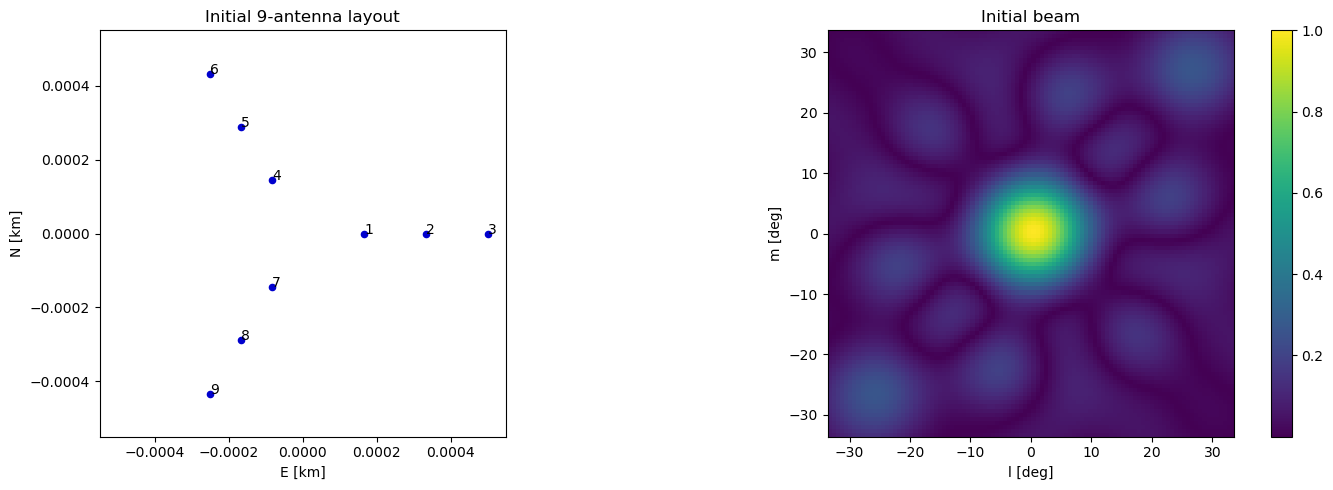

In [112]:
#Observation configuration:
schedule = aou.exp_decay_schedule(init_lr=0.05, end_lr=0.005, transition_steps=500, decay_rate=0.5)
optimizer = aou.make_optimizer('adam', lr=schedule)

config = aou.ObservationConfig(
    npx=npx, fov=FOV,          # FOV = lambda / D_max, converted to degrees
    lat=lat, dec=lat,          #lat is the latitude of the array, dec is the declination of the source (aka milky way)
    freq=frequency/u.Hz, bw=bw, n_freqs=n_freqs, n_times=n_times,
    track_h=track_h, t_0=t_0, kernel_W=kernel_W)

#Initial antenna layout:
antenna_init = jnp.asarray(aat.y_antenna_arr(n_antenna=N_ANT//3, r=SITE_LIM,))

# Centre the array on its mean position
antenna_init = antenna_init - jnp.mean(antenna_init, axis=0, keepdims=True)
print('Antennas :', antenna_init.shape, '  baselines:', N_ANT*(N_ANT-1))

forward_fn = lambda antenna: aou.antenna_to_beam(antenna, config)      #Klopt deze antenna to beam/maakt dat uit?
beam0 = forward_fn(antenna_init)
print('beam shape :', beam0.shape, '  peak:', float(beam0.max()))

#2D angular distance map, needed for the airy beam
npx = config.npx
pixel_scale = (config.fov*u.deg).to(u.rad).value / npx
x = (np.arange(npx) - npx // 2) * pixel_scale
y = (np.arange(npx) - npx // 2) * pixel_scale
xx, yy = np.meshgrid(x, y)
angular_distance = np.sqrt(xx**2 + yy**2) * u.rad

airy_fn = airy_beam_fn(1.22 * (wavelength/u.m) / diam_ant *180/np.pi *u.deg)
primary_beam = airy_fn(angular_distance)
combined_beam = np.array(beam0) * primary_beam

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
apu.plot_antenna_arr(antenna_init, ax=axes[0], fig=fig, title=f'Initial {N_ANT}-antenna layout')
apu.plot_sky(np.array(combined_beam),       (config.fov, config.fov), axes[1], fig, title='Initial beam')
plt.tight_layout(); plt.show()


In [113]:
#initial optimization settings, this code wants to optimize total the beam to a perfect gauss. As this is not achievable for us, we 
#use different optimizations in the next cells
def log_spaced_indexes(n_steps, n_snapshots, min_spacing=15):
    """Generate log-spaced indexes with a minimum spacing constraint."""
    # Generate more than needed to ensure we can filter down to n_snapshots
    candidate_indexes = np.unique(np.round(np.logspace(0, np.log10(n_steps), n_snapshots)).astype(int))
    min_spacing_break = np.argmin((candidate_indexes[1:] - candidate_indexes[:-1] - 15)**2)
    linear_indexes = np.arange(candidate_indexes[min_spacing_break], n_steps, min_spacing)
    full_indexes = np.unique(np.concatenate((candidate_indexes[:min_spacing_break], linear_indexes)))
    return full_indexes
snapshot_steps = log_spaced_indexes(n_steps, n_snapshots=100, min_spacing=15)

# Target dirty beam: sub-natural FWHM (half the theoretical resolution) forces UV reshaping
LAMBDA   = wavelength/u.m #freq to wavelength
fwhm_rad = LAMBDA / R_MAX
fwhm_pix = fwhm_rad * 180/np.pi / (config.fov / config.npx) 

target_beam = jnp.array(adu.gauss_source(config.npx, config.npx, fwhm_pix=fwhm_pix/2*1.3))

loss_fn = aou.make_loss_fn(
    forward_fn=forward_fn,
    target_loss_fn=lambda beam: aou.beam_mse_loss(beam, target_beam),
    constraints=constraints,
)

print('Initial total loss :', float(loss_fn(antenna_init)))
for c in constraints:
    print(f'  {c.name:8s} penalty = {float(c.fn(antenna_init)):.5g}  (w={c.weight})')
print('mse loss = ', float(aou.beam_mse_loss(forward_fn(antenna_init), target_beam)))

result = aou.optimise_array(
    antenna_init=antenna_init,
    loss_fn=loss_fn,
    optimizer=optimizer,
    n_steps=n_steps,
    snapshot_steps=snapshot_steps,
    freeze_u=True,
    verbose_every=50,)

antenna       = result['antenna']
loss_history  = result['loss_history']
snap_ant      = result['snapshots_antenna']
snap_loss     = result['snapshots_loss']
snapshot_step = result['snapshots_step']

print()
#print(f'\nFinal loss = {loss_history[-1]:.5f}   (initial = {loss_history[0]:.5f})')
print(f'Snapshots : {len(snap_ant)}  (steps: {snapshot_step[:6].tolist()} ... {snapshot_step[-3:].tolist()})')

Initial total loss : 1.6912744343562471
  spacing  penalty = 0.16667  (w=10)
  radius   penalty = 1.1999e-23  (w=10)
  centroid penalty = 1.9022e-34  (w=10)
mse loss =  0.024607767689580982
step    0   loss = 1.69127
step   50   loss = 0.01052
step  100   loss = 0.00792
step  150   loss = 0.00716
step  200   loss = 0.00639
step  250   loss = 0.00623
step  300   loss = 0.00612
step  350   loss = 0.00605
step  400   loss = 0.00605
step  450   loss = 0.00602
step  500   loss = 0.00601
step  550   loss = 0.00597
step  600   loss = 0.00589
step  650   loss = 0.00548
step  700   loss = 0.00509
step  750   loss = 0.00485
step  800   loss = 0.00463
step  850   loss = 0.00445
step  900   loss = 0.00435
step  950   loss = 0.00428
step 1000   loss = 0.00424
step 1050   loss = 0.00422
step 1100   loss = 0.00419
step 1150   loss = 0.00418
step 1200   loss = 0.00416
step 1250   loss = 0.00414
step 1300   loss = 0.00414
step 1350   loss = 0.00413
step 1400   loss = 0.00411
step 1450   loss = 0.00412


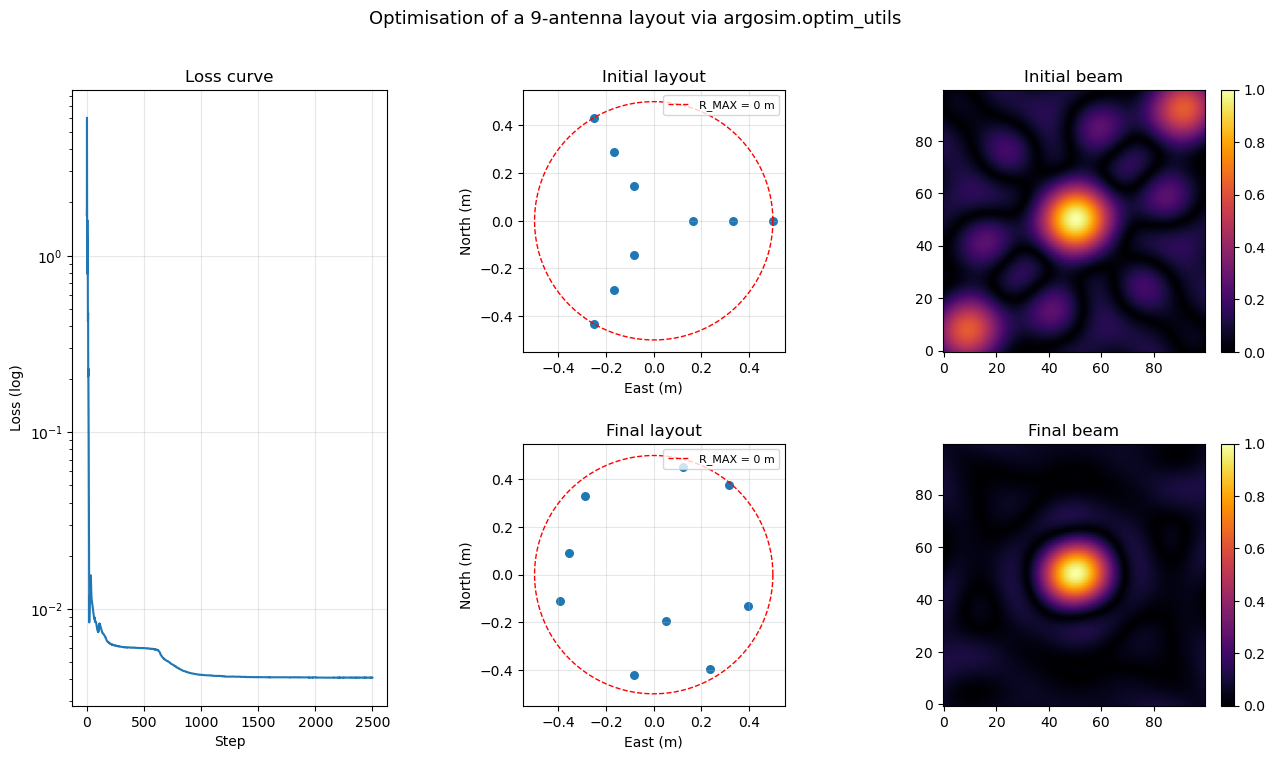

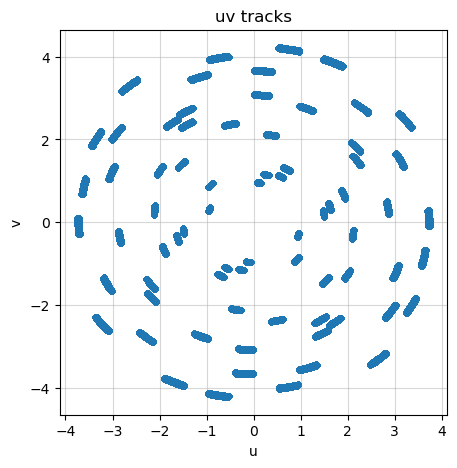

In [41]:
#Plotting results
beam_final   = np.array(forward_fn(antenna))
beam_initial = np.array(forward_fn(antenna_init))
ant_final = np.array(antenna)
ant_init  = np.array(antenna_init)

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35)

ax_loss = fig.add_subplot(gs[:, 0])
ax_loss.semilogy(loss_history)
ax_loss.set_xlabel('Step')
ax_loss.set_ylabel('Loss (log)')
ax_loss.set_title('Loss curve')
ax_loss.grid(True, alpha=0.3)

theta = np.linspace(0, 2*np.pi, 200)

for row, (arr, label) in enumerate([(ant_init, 'Initial'), (ant_final, 'Final')]):
    ax = fig.add_subplot(gs[row, 1])
    ax.scatter(arr[:, 0], arr[:, 1], s=30)

    cx, cy = arr[:, 0].mean(), arr[:, 1].mean()
    ax.plot(
        cx + R_MAX*np.cos(theta),
        cy + R_MAX*np.sin(theta),
        'r--', lw=1,
        label=f'R_MAX = {R_MAX:.1f} m'
    )

    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_ylim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_title(f'{label} layout')

vmax = max(beam_initial.max(), beam_final.max())

for row, (img, label) in enumerate([
    (beam_initial, 'Initial beam'),
    (beam_final, 'Final beam')]):
        ax = fig.add_subplot(gs[row, 2])
        im = ax.imshow(img, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
        plt.colorbar(im, ax=ax, fraction=0.046)
        ax.set_title(label)

plt.suptitle(f'Optimisation of a {N_ANT}-antenna layout via argosim.optim_utils',fontsize=13)
plt.show()

b_optim = aat.get_baselines(ant_final)
uv_optim = uv_tracks(b_optim, track_time=track_h, n_times=20, lat=lat_deg,dec=lat_deg,f=frequency/u.Hz)
plot_uv(uv_optim)

Minimum baseline: 0.16666666666666663 m
Maximum baseline: 0.8660254037844388 m
Maximum physical baseline: 0.8660254037844388
Maximum UV radius: 3.090541107947844


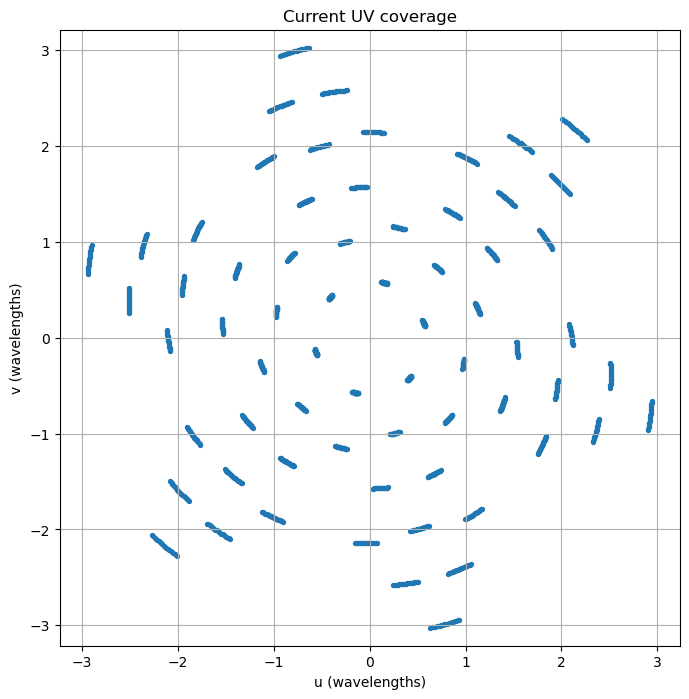

In [42]:
#Optimization function based on uv coverage; change some functions:

def antenna_to_uv(antenna, config):

    b_enu = aat.get_baselines(antenna)
    
    track, _ = aat.uv_track_multiband(
        b_ENU=b_enu,
        lat=config.lat,
        dec=config.dec,
        track_time=config.track_h,
        t_0=config.t_0,
        n_times=config.n_times,
        f=config.freq,
        df=config.bw,
        n_freqs=config.n_freqs,
        multi_band=False,)

    return track, b_enu

uv_samples, baselines = antenna_to_uv(antenna_init, config)
baseline_lengths = np.linalg.norm(baselines, axis=1)

print("Minimum baseline:", baseline_lengths.min(), "m")
print("Maximum baseline:", baseline_lengths.max(), "m")

print("Maximum physical baseline:",
      np.linalg.norm(baselines, axis=1).max())

print("Maximum UV radius:",
      np.linalg.norm(uv_samples[:, :2], axis=1).max())

uv = np.array(uv_samples)

plt.figure(figsize=(8, 8))
plt.scatter(uv[:, 0], uv[:, 1], s=8)
plt.xlabel('u (wavelengths)')
plt.ylabel('v (wavelengths)')
plt.title('Current UV coverage')
plt.axis('equal')
plt.grid()
plt.show()

In [44]:
#change the optimisation function; consists of two parts, uv-uniformity and baseline-uniformity, will be applied in target_loss_fn
#furthermore, forward_fn will be changed from antenna_to_beam to antenna_to_uv

print(uv_samples.shape)

#We want to specify the uniformity by one single number
#We minimize this in the loss fcn
def calculate_uniformity(uv_samples, uv_radius, n_grid=20, sigma=None):

    #u and v coordinates for all baselines, basically slicing out W
    uv = uv_samples[:, :2]  #shape uv = (1440,3), 1440 = N(N-1)(n_times) = 9x8x20 ,3 = (x,y,x)

    #defining the grid spacing, diameter is divided into 20 parts in each direction
    grid_spacing = 2 * uv_radius / n_grid

    #define sigma for the gaussian smoothing, this way a peak contributes about 13.8% to neighbouring cells, 
    #we smooth because Adam cannot handle delta peaks
    if sigma is None:
        sigma = grid_spacing / 2

    #define uv grid, between centres of first and last cells, 
    grid = jnp.linspace(-uv_radius + grid_spacing / 2, uv_radius - grid_spacing / 2, n_grid)

    #making it 2d
    U, V = jnp.meshgrid(grid, grid)

    #this has shape 400,2, the u and v for every grid point, to which we will compare the actual uv coverage
    grid_points = jnp.stack([U.ravel(), V.ravel()], axis=1)

    #only include cells inside the circular UV region
    mask = jnp.sum(grid_points**2, axis=1) <= uv_radius**2

    #calculate distances from every UV sample to every grid cell, needed for the gaussian smoothing
    #we now know how far every UV sample is from every grid-cell centre
    distances_squared = jnp.sum((uv[:, None, :] - grid_points[None, :, :])**2, axis=2    )

    #gaussian smoothing
    weights = jnp.exp(-distances_squared / (2 * sigma**2))

    #exclude cells outside the circular region
    weights = weights * mask[None, :]

    #normalise each sample's contribution, so samples on the circle edge contribute as much
    weights = weights / (jnp.sum(weights, axis=1, keepdims=True) + 1e-12)

    #total sampling density per cell --> determines how much UV contributes for each of the cells
    counts = jnp.sum(weights, axis=0)

    #calculate thee mean density inside the UV region
    n_cells = jnp.sum(mask)
    mean_density = jnp.sum(counts) / n_cells

    # Normalised variance of the sampling density
    variance = jnp.sum(mask * (counts - mean_density)**2) / n_cells

    #divide by mean^2 because that makes it dimensionless, independent of amount of UV samples
    #twice as many samples --> variance 4x as large
    uniformity = variance / (mean_density**2 + 1e-12)

    return uniformity

#spacing of the baselines
def calculate_baseline_uniformity(antenna, n_bins=20, sigma=None):

    #antenna input is position array
    
    #get all of the baselines, array of distances between antennas in x,y,z
    baselines = aat.get_baselines(antenna)

    #calculate 1-dimensional distances
    lengths = jnp.sqrt(jnp.sum(baselines**2, axis=1))

    #define min and max allowed/wanted baselines
    min_length = D_MIN
    max_length = 2 * R_MAX

    #define the grid in length coords
    bin_spacing = (max_length - min_length) / n_bins

    #smoothing sigma
    if sigma is None:
        sigma = bin_spacing / 2

    #define grid
    bins = jnp.linspace(min_length + bin_spacing / 2,max_length - bin_spacing / 2,n_bins)

    #define distance (squared) of each length to each bin centre, this is needed for the gauss.
    distances_squared = (lengths[:, None] - bins[None, :])**2

    #assign weights
    weights = jnp.exp(-distances_squared / (2 * sigma**2))

    #normalize weights
    weights = weights / (jnp.sum(weights, axis=1, keepdims=True) + 1e-12)

    #count total contribution to each bin
    counts = jnp.sum(weights, axis=0)

    #determine mean contribution
    mean_density = jnp.mean(counts)

    #determine variance
    variance = jnp.mean((counts - mean_density)**2)
    
    uniformity = variance / (mean_density**2 + 1e-12)

    return uniformity


(1440, 3)


In [45]:
#running the optimization
UV_RADIUS = 2 * R_MAX / wavelength/u.m

uniformity_loss = calculate_uniformity(antenna_to_uv(antenna_init,config)[0],UV_RADIUS)
baseline_loss = calculate_baseline_uniformity(antenna_init)

print("Initial uniformity loss:", float(uniformity_loss))
print("Initial baseline uniformity loss:", float(baseline_loss))

#apply weighting for both constraints
W_UV = 1.0
W_BASELINE = 1.0

#combine both requirements in a loss fcn
def combined_loss(antenna):

    uv = antenna_to_uv(antenna, config)[0]
    uv_loss = calculate_uniformity(uv,uv_radius=UV_RADIUS,n_grid=20)

    baseline_loss = calculate_baseline_uniformity(antenna)

    L = W_UV * uv_loss + W_BASELINE * baseline_loss

    for c in constraints:
        L = L + c.weight * c.fn(antenna)

    return L

print("Combined loss:", float(combined_loss(antenna_init)))

Initial uniformity loss: 2.131550355182404
Initial baseline uniformity loss: 0.9864745402420582
Combined loss: 4.784691562091128


In [46]:
#Running the optimisation
result = aou.optimise_array(
    antenna_init=antenna_init,
    loss_fn=combined_loss,
    optimizer=optimizer,
    n_steps=n_steps,
    snapshot_steps=snapshot_steps,
    freeze_u=True,
    verbose_every=50,
)

antenna       = result['antenna']
loss_history  = result['loss_history']
snap_ant      = result['snapshots_antenna']
snap_loss     = result['snapshots_loss']
snapshot_step = result['snapshots_step']

print(f'\nFinal loss = {loss_history[-1]:.5f}   (initial = {loss_history[0]:.5f})')
print(f'Snapshots : {len(snap_ant)}  (steps: {snapshot_step[:6].tolist()} ... {snapshot_step[-3:].tolist()})')


step    0   loss = 4.78469
step   50   loss = 1.24052
step  100   loss = 1.14877
step  150   loss = 1.14841
step  200   loss = 1.14841
step  250   loss = 1.14841
step  300   loss = 1.14841
step  350   loss = 1.14841
step  400   loss = 1.14841
step  450   loss = 1.14841
step  500   loss = 1.14841
step  550   loss = 1.14841
step  600   loss = 1.14841
step  650   loss = 1.14841
step  700   loss = 1.14841
step  750   loss = 1.14841
step  800   loss = 1.14841
step  850   loss = 1.14841
step  900   loss = 1.14841
step  950   loss = 1.14841
step 1000   loss = 1.14841
step 1050   loss = 1.14841
step 1100   loss = 1.14841
step 1150   loss = 1.14841
step 1200   loss = 1.14841
step 1250   loss = 1.14841
step 1300   loss = 1.14841
step 1350   loss = 1.14841
step 1400   loss = 1.14841
step 1450   loss = 1.14841
step 1500   loss = 1.14841
step 1550   loss = 1.14841
step 1600   loss = 1.14841
step 1650   loss = 1.14841
step 1700   loss = 1.14841
step 1750   loss = 1.14841
step 1800   loss = 1.14841
s

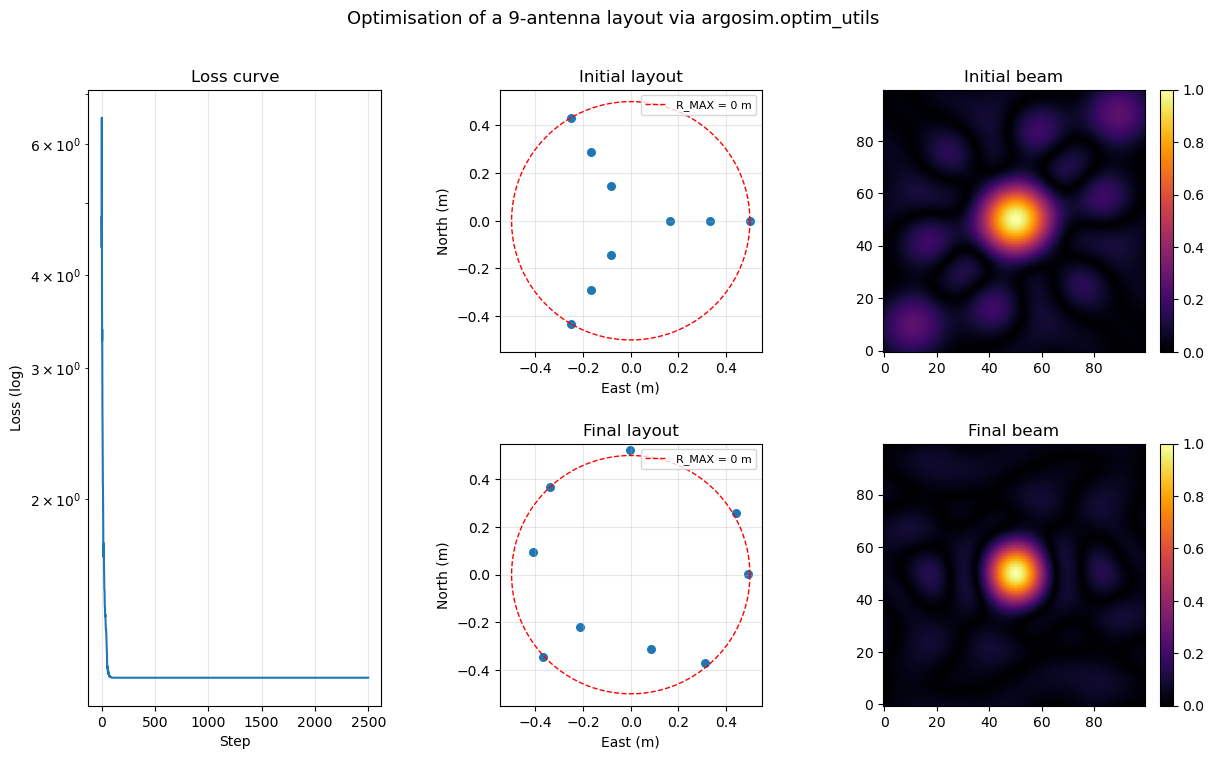

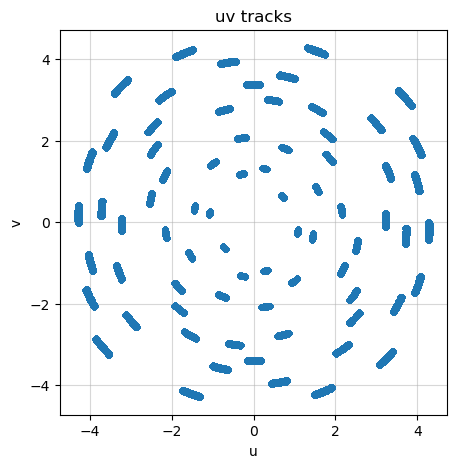

In [47]:
#Plotting the results
ant_final = np.array(antenna)
ant_init = np.array(antenna_init)
beam_final = np.array(forward_fn(antenna)) * primary_beam
beam_initial = np.array(forward_fn(antenna_init)) * primary_beam


fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35)

ax_loss = fig.add_subplot(gs[:, 0])
ax_loss.semilogy(loss_history)
ax_loss.set_xlabel('Step')
ax_loss.set_ylabel('Loss (log)')
ax_loss.set_title('Loss curve')
ax_loss.grid(True, alpha=0.3)

theta = np.linspace(0, 2*np.pi, 200)

for row, (arr, label) in enumerate([(ant_init, 'Initial'), (ant_final, 'Final')]):
    ax = fig.add_subplot(gs[row, 1])
    ax.scatter(arr[:, 0], arr[:, 1], s=30)
    cx, cy = arr[:, 0].mean(), arr[:, 1].mean()
    ax.plot(cx + R_MAX*np.cos(theta), cy + R_MAX*np.sin(theta),
            'r--', lw=1, label=f'R_MAX = {R_MAX:.1f} m')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_ylim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_title(f'{label} layout')

vmax = max(beam_initial.max(), beam_final.max())

for row, (img, label) in enumerate([(beam_initial, 'Initial beam'), (beam_final, 'Final beam')]):
    ax = fig.add_subplot(gs[row, 2])
    im = ax.imshow(img, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_title(label)

plt.suptitle(f'Optimisation of a {N_ANT}-antenna layout via argosim.optim_utils',
             fontsize=13)
plt.show()

b_optim = aat.get_baselines(ant_final)
uv_optim = uv_tracks(b_optim, track_time=track_h, n_times=20,
                     lat=lat_deg, dec=lat_deg, f=frequency/u.Hz)
plot_uv(uv_optim)


In [48]:
#check whether we should manually include opposite samples; no!

uv = uv_samples[:, :2]

# Calculate the opposite of every UV sample
uv_opposite = -uv

# Check whether each opposite sample exists in the original array
distances = jnp.sqrt(jnp.sum((uv[:, None, :] - uv_opposite[None, :, :])**2,axis=2))

# Find the closest match for each sample
closest_distances = jnp.min(distances, axis=1)

print("Maximum distance to an opposite sample:",jnp.max(closest_distances))

Maximum distance to an opposite sample: 1.047382306668854e-15


Minimum baseline: 0.2000430915900743 m
Maximum baseline: 1.0126115897378305 m


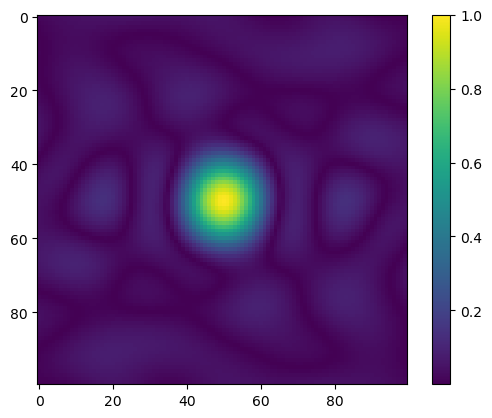

The max of the psf is at pixel 50 50 with value 0.999999999947219
The 2nd max of the psf is at pixel 49 50 with value 0.9926935914155519
The PSF has a unique maximum


In [49]:
baseline_lengths = np.linalg.norm(b_optim, axis=1)

print("Minimum baseline:", baseline_lengths.min(), "m")
print("Maximum baseline:", baseline_lengths.max(), "m")

#beam psf findings
plt.figure()
plt.imshow(beam_final)
plt.colorbar()
plt.show()

beam_final_2 = beam_final.copy()
row_max, col_max = np.unravel_index(beam_final_2.argmax(), beam_final_2.shape)

print('The max of the psf is at pixel',row_max,col_max, 'with value', beam_final_2[row_max,col_max])

beam_final_masked = beam_final_2.copy()
beam_final_masked[row_max,col_max] = 0.0
row_masked, col_masked = np.unravel_index(beam_final_masked.argmax(), beam_final_masked.shape)

print('The 2nd max of the psf is at pixel',row_masked,col_masked, 'with value', beam_final_masked[row_masked,col_masked])

if beam_final_masked[row_masked,col_masked] <  beam_final_2[row_max,col_max]:
    print('The PSF has a unique maximum')
else: 
    pass

In [50]:
def resolution(Bmax):
    return (wavelength/u.m)/Bmax

print('The resolution of the interferometer is',resolution(baseline_lengths.max())*u.deg)

#mask the main lobe
beam_final_masked_center = beam_final.copy()
radius = 14  # chosen based on the width of the main lobe

Y, X = np.ogrid[:beam_final.shape[0], :beam_final.shape[1]]
main_lobe_mask = (Y - row_max)**2 + (X - col_max)**2 <= radius**2
beam_final_masked_center[main_lobe_mask] = 0.0

#find maximum sidelobe
max_sidelobe = np.max(np.abs(beam_final_masked_center))

#calculate relative sidelobe level
max_sll = max_sidelobe / abs(beam_final[row_max, col_max])

# Convert to dB
max_sll_dB = 20 * np.log10(max_sll)

print('Maximum sidelobe level:', max_sll)
print('Maximum sidelobe level:', max_sll_dB, 'dB')


#select all pixels outside the main lobe
sidelobes = beam_final[~main_lobe_mask]

#calculate RMS sidelobe level
rms_sidelobe = np.sqrt(np.mean(sidelobes**2))

#normalise relative to central peak
rms_sll = rms_sidelobe / abs(beam_final[row_max, col_max])
rms_sll_dB = 20 * np.log10(rms_sll)

print('RMS sidelobe level:', rms_sll)
print('RMS sidelobe level:', rms_sll_dB, 'dB')

The resolution of the interferometer is 0.20849203330808697 deg
Maximum sidelobe level: 0.18138784057656773
Maximum sidelobe level: -14.827836588902741 dB
RMS sidelobe level: 0.04784642618402677
RMS sidelobe level: -26.40300991281925 dB


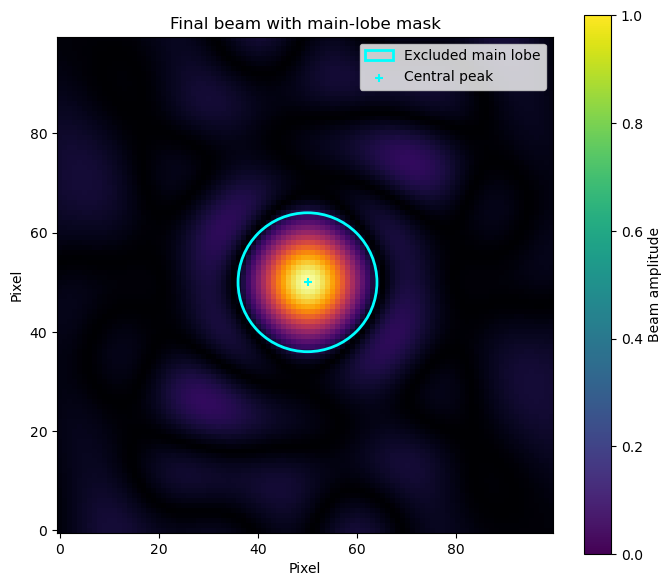

In [24]:
plt.figure(figsize=(8, 7))
plt.imshow(beam_final, origin='lower', cmap='inferno')

# Plot the main-lobe mask boundary
circle = plt.Circle(
    (col_max, row_max),
    radius,
    color='cyan',
    fill=False,
    linewidth=2,
    label='Excluded main lobe')

plt.gca().add_patch(circle)
plt.scatter(col_max, row_max, color='cyan', marker='+', label='Central peak')
plt.colorbar(label='Beam amplitude')
plt.legend()
plt.title('Final beam with main-lobe mask')
plt.xlabel('Pixel')
plt.ylabel('Pixel')
plt.show()

uv samples: (1440, 3)


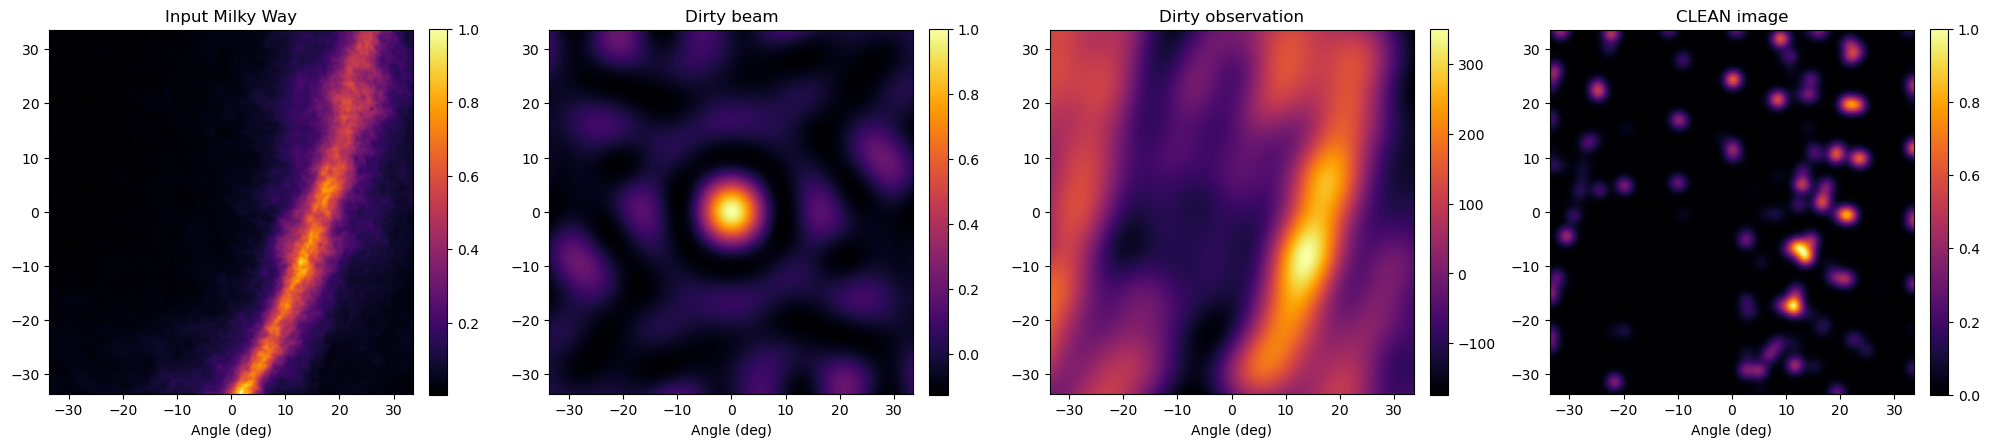

In [51]:
#Observing the sky imaging:
#uv_circ  = antenna_utils.uv_track_multiband(antenna, lat=lat_deg, dec=lat_deg, track_time=track_h, n_times=n_times,f=frequency)

#plt.figure()
#plt.imshow(sky_MW)
#plt.show()

#MW_png = Image.open('HI4PI_20_11.png')
#MW_png = MW_png.resize((256, 256))

#sky_MW = np.array(MW_png)
#sky_MW = np.array(MW_png.convert('L'))

#print(antenna)


#FOV = 256 * 20 / 60 * u.deg #85, from the image itself

#this FOV is for one antenna?, and in deg??
#airy_beam = AiryBeam(r_to_first_null=((1.22 * wavelength/(u.m) / diam_ant)*180/np.pi)*u.deg, n_pix=sky_MW.shape[0], fov_deg=FOV.value / 2)
#obs,dirty_beam = imaging_utils.simulate_dirty_observation(sky_MW, uv_circ, FOV.value, multi_band=True,beam = airy_beam,freqs=[frequency])
#plot_utils.plot_sky(dirty_beam[0],FOV.value,title='Dirty beam')
#plot_utils.plot_sky(obs[0],(FOV.value,FOV.value), title='Observation')


#plt.figure()
#plt.imshow(sky_double_gauss, origin='lower', extent=[-FOV_sky/2, FOV_sky/2]*2)
#plt.show()

#print(obs[0].shape)
b_final = aat.get_baselines(np.array(antenna))
uv_obs = antenna_utils.uv_track_multiband(
    b_final, lat=lat, dec=lat,
    track_time=track_h, t_0=t_0, n_times=n_times, f=frequency)
print("uv samples:", uv_obs[0].shape)

airy_beam = AiryBeam(r_to_first_null=r_to_first_null.value,
                     n_pix=n_pix, fov_deg=FOV_sky/2)

obs, dirty_beam = imaging_utils.simulate_dirty_observation(
    sky_MW, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])

#plot_utils.plot_sky(dirty_beam[0], (FOV_sky, FOV_sky), title='Dirty beam')
#plot_utils.plot_sky(obs[0],        (FOV_sky, FOV_sky), title='Observation')

from argosim.clean import *
I_clean, sky_model = clean_hogbom(obs[0], dirty_beam[0], gamma=0.1, max_iter=1000,
                                  threshold=1e-3, clean_beam_size_px=10, res=False)
I_clean /= np.max(I_clean)
#plot_utils.plot_sky(I_clean, (FOV_sky, FOV_sky), title='CLEAN image')


# Generate CLEAN image
from argosim.clean import *

I_clean, sky_model = clean_hogbom(
    obs[0],
    dirty_beam[0],
    gamma=0.1,
    max_iter=1000,
    threshold=1e-3,
    clean_beam_size_px=10,
    res=False
)

I_clean /= np.max(I_clean)


# Plot all four images next to each other
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

images = [
    sky_MW,
    dirty_beam[0],
    obs[0],
    I_clean
]

titles = [
    "Input Milky Way",
    "Dirty beam",
    "Dirty observation",
    "CLEAN image"
]

for i in range(4):

    im = ax[i].imshow(
        images[i],
        origin='lower',
        extent=[-FOV_sky/2, FOV_sky/2,
                -FOV_sky/2, FOV_sky/2],
        cmap='inferno'
    )

    ax[i].set_title(titles[i])
    ax[i].set_xlabel("Angle (deg)")
    ax[i].set_aspect('equal')

    plt.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04)

plt.tight_layout()
# plt.savefig('9_ant_0.4m_Yconfig_result.pdf')
plt.show()

<font size="5">
ARRAY OPTIMISATION -- CIRCLE
<font>


Antennas : (9, 3)   baselines: 72
beam shape : (100, 100)   peak: 0.9999999999533368


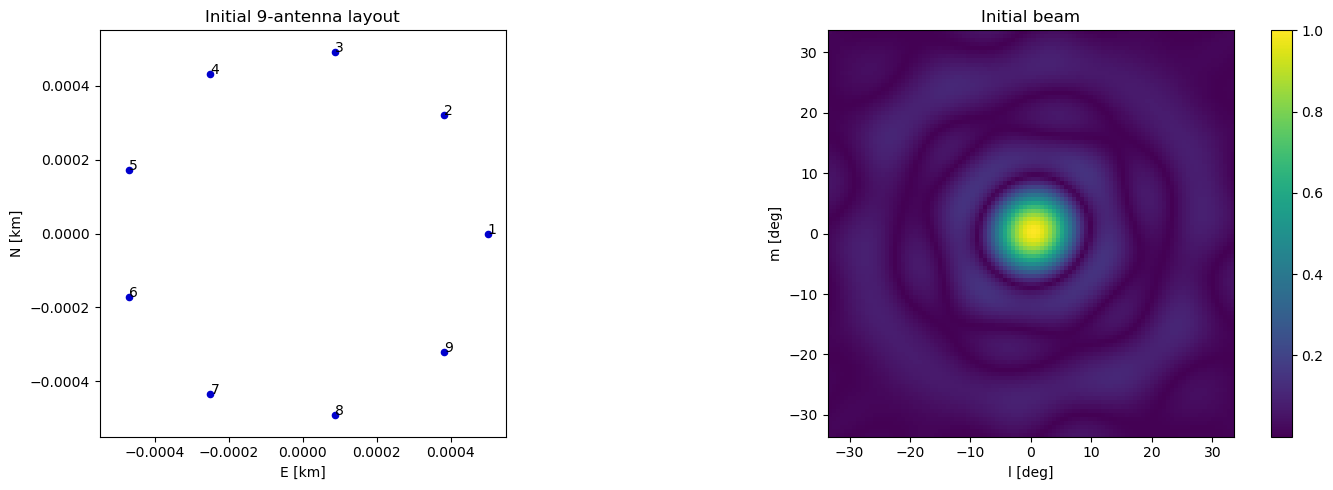

In [52]:
#repeat for an initial circular array:

#Initial antenna layout:
antenna_init = jnp.asarray(aat.circular_antenna_arr(n_antenna=N_ANT, r=SITE_LIM,))

# Centre the array on its mean position
antenna_init = antenna_init - jnp.mean(antenna_init, axis=0, keepdims=True)
print('Antennas :', antenna_init.shape, '  baselines:', N_ANT*(N_ANT-1))

forward_fn = lambda antenna: aou.antenna_to_beam(antenna, config)      #Klopt deze antenna to beam/maakt dat uit?
beam0 = forward_fn(antenna_init)
print('beam shape :', beam0.shape, '  peak:', float(beam0.max()))

#2D angular distance map, needed for the airy beam
npx = config.npx
pixel_scale = (config.fov*u.deg).to(u.rad).value / npx
x = (np.arange(npx) - npx // 2) * pixel_scale
y = (np.arange(npx) - npx // 2) * pixel_scale
xx, yy = np.meshgrid(x, y)
angular_distance = np.sqrt(xx**2 + yy**2) * u.rad

airy_fn = airy_beam_fn(1.22 * (wavelength/u.m) / diam_ant *180/np.pi *u.deg)
primary_beam = airy_fn(angular_distance)
combined_beam = np.array(beam0) * primary_beam

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
apu.plot_antenna_arr(antenna_init, ax=axes[0], fig=fig, title=f'Initial {N_ANT}-antenna layout')
apu.plot_sky(np.array(combined_beam),       (config.fov, config.fov), axes[1], fig, title='Initial beam')
plt.tight_layout(); plt.show()

Minimum baseline: 0.3420201433256686 m
Maximum baseline: 0.9848077530122081 m
Maximum physical baseline: 0.9848077530122081
Maximum UV radius: 3.514433676898874


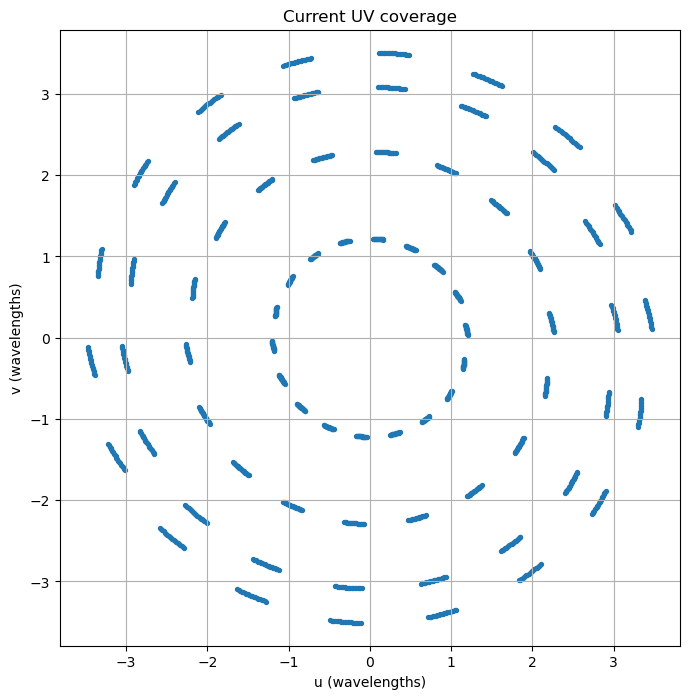

In [53]:
uv_samples, baselines = antenna_to_uv(antenna_init, config)
baseline_lengths = np.linalg.norm(baselines, axis=1)

print("Minimum baseline:", baseline_lengths.min(), "m")
print("Maximum baseline:", baseline_lengths.max(), "m")

print("Maximum physical baseline:",
      np.linalg.norm(baselines, axis=1).max())

print("Maximum UV radius:",
      np.linalg.norm(uv_samples[:, :2], axis=1).max())

uv = np.array(uv_samples)

plt.figure(figsize=(8, 8))
plt.scatter(uv[:, 0], uv[:, 1], s=8)
plt.xlabel('u (wavelengths)')
plt.ylabel('v (wavelengths)')
plt.title('Current UV coverage')
plt.axis('equal')
plt.grid()
plt.show()

In [54]:
uniformity_loss = calculate_uniformity(antenna_to_uv(antenna_init,config)[0],UV_RADIUS)
baseline_loss = calculate_baseline_uniformity(antenna_init)

print("Initial uniformity loss:", float(uniformity_loss))
print("Initial baseline uniformity loss:", float(baseline_loss))

print("Combined loss:", float(combined_loss(antenna_init)))

Initial uniformity loss: 1.117417444643035
Initial baseline uniformity loss: 2.2439146343811447
Combined loss: 3.3613320790241796


In [55]:
#Running the optimisation
result = aou.optimise_array(
    antenna_init=antenna_init,
    loss_fn=combined_loss,
    optimizer=optimizer,
    n_steps=n_steps,
    snapshot_steps=snapshot_steps,
    freeze_u=True,
    verbose_every=50,
)

antenna       = result['antenna']
loss_history  = result['loss_history']
snap_ant      = result['snapshots_antenna']
snap_loss     = result['snapshots_loss']
snapshot_step = result['snapshots_step']

print(f'\nFinal loss = {loss_history[-1]:.5f}   (initial = {loss_history[0]:.5f})')
print(f'Snapshots : {len(snap_ant)}  (steps: {snapshot_step[:6].tolist()} ... {snapshot_step[-3:].tolist()})')


step    0   loss = 3.36133
step   50   loss = 1.11019
step  100   loss = 1.08912
step  150   loss = 1.08895
step  200   loss = 1.08895
step  250   loss = 1.08895
step  300   loss = 1.08895
step  350   loss = 1.08895
step  400   loss = 1.08895
step  450   loss = 1.08895
step  500   loss = 1.08895
step  550   loss = 1.08895
step  600   loss = 1.08895
step  650   loss = 1.08895
step  700   loss = 1.08895
step  750   loss = 1.08895
step  800   loss = 1.08895
step  850   loss = 1.08895
step  900   loss = 1.08895
step  950   loss = 1.08895
step 1000   loss = 1.08895
step 1050   loss = 1.08895
step 1100   loss = 1.08895
step 1150   loss = 1.08895
step 1200   loss = 1.08895
step 1250   loss = 1.08895
step 1300   loss = 1.08895
step 1350   loss = 1.08895
step 1400   loss = 1.08895
step 1450   loss = 1.08895
step 1500   loss = 1.08895
step 1550   loss = 1.08895
step 1600   loss = 1.08895
step 1650   loss = 1.08895
step 1700   loss = 1.08895
step 1750   loss = 1.08895
step 1800   loss = 1.08895
s

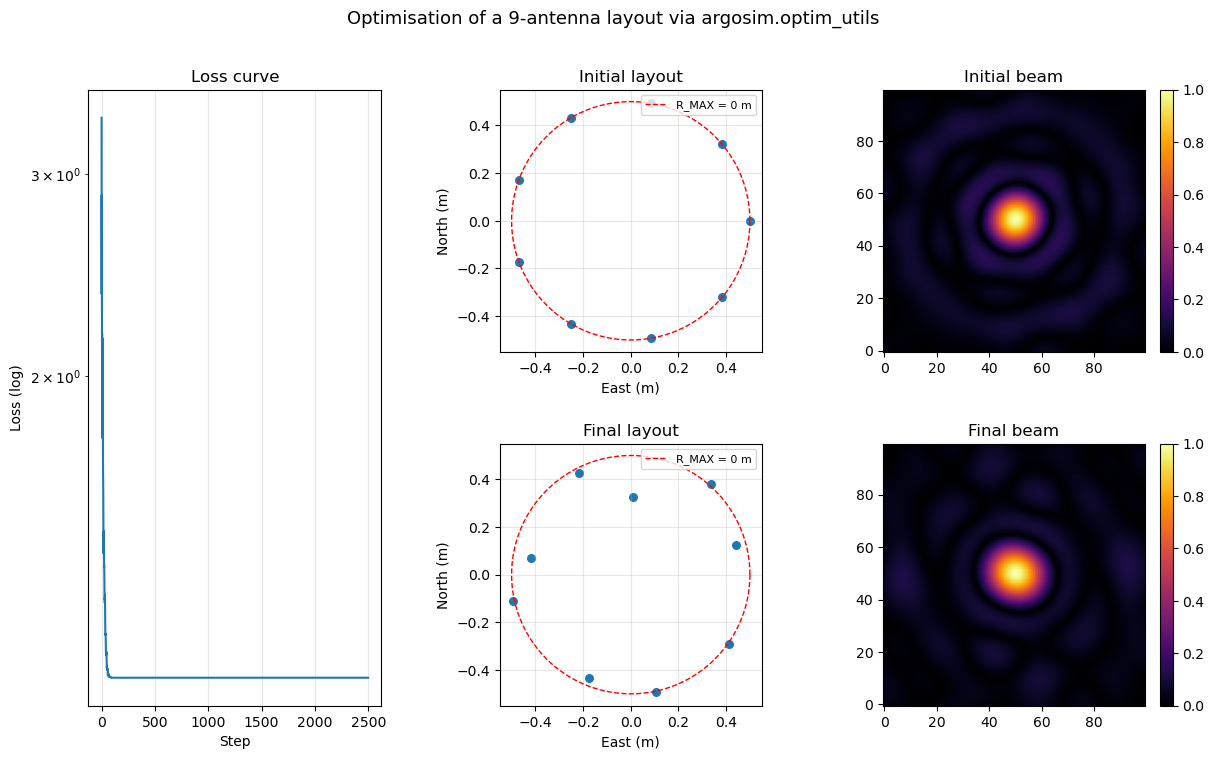

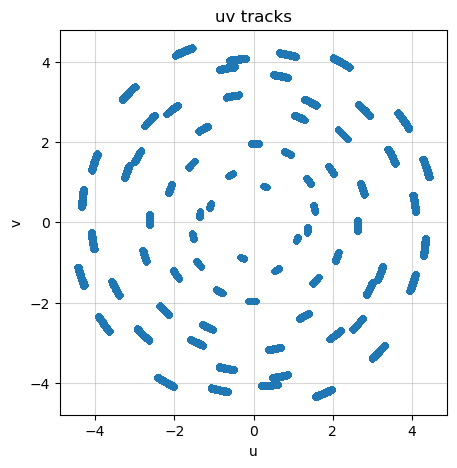

In [56]:
#Plotting the results
ant_final = np.array(antenna)
ant_init = np.array(antenna_init)
beam_final = np.array(forward_fn(antenna)) * primary_beam
beam_initial = np.array(forward_fn(antenna_init)) * primary_beam


fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35)

ax_loss = fig.add_subplot(gs[:, 0])
ax_loss.semilogy(loss_history)
ax_loss.set_xlabel('Step')
ax_loss.set_ylabel('Loss (log)')
ax_loss.set_title('Loss curve')
ax_loss.grid(True, alpha=0.3)

theta = np.linspace(0, 2*np.pi, 200)

for row, (arr, label) in enumerate([(ant_init, 'Initial'), (ant_final, 'Final')]):
    ax = fig.add_subplot(gs[row, 1])
    ax.scatter(arr[:, 0], arr[:, 1], s=30)
    cx, cy = arr[:, 0].mean(), arr[:, 1].mean()
    ax.plot(cx + R_MAX*np.cos(theta), cy + R_MAX*np.sin(theta),
            'r--', lw=1, label=f'R_MAX = {R_MAX:.0f} m')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_ylim(-SITE_LIM*1.1, SITE_LIM*1.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('East (m)')
    ax.set_ylabel('North (m)')
    ax.set_title(f'{label} layout')

vmax = max(beam_initial.max(), beam_final.max())

for row, (img, label) in enumerate([(beam_initial, 'Initial beam'), (beam_final, 'Final beam')]):
    ax = fig.add_subplot(gs[row, 2])
    im = ax.imshow(img, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_title(label)

plt.suptitle(f'Optimisation of a {N_ANT}-antenna layout via argosim.optim_utils',
             fontsize=13)
plt.show()

b_optim = aat.get_baselines(ant_final)
uv_optim = uv_tracks(b_optim, track_time=track_h, n_times=20,
                     lat=lat_deg, dec=lat_deg, f=frequency/u.Hz)
plot_uv(uv_optim)


Minimum baseline: 0.16127865626487764 m
Maximum baseline: 1.0045091946464948 m


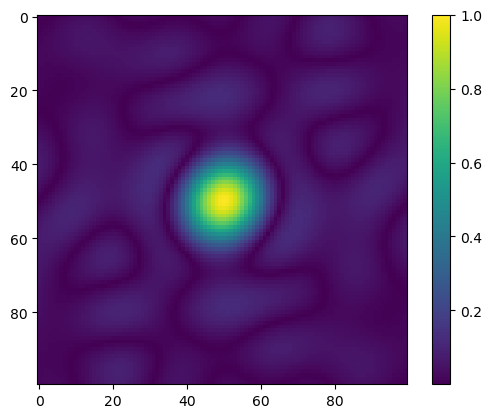

The max of the psf is at pixel 50 50 with value 0.9999999999504596
The 2nd max of the psf is at pixel 49 50 with value 0.9921292162316567
The PSF has a unique maximum


In [31]:
baseline_lengths = np.linalg.norm(b_optim, axis=1)

print("Minimum baseline:", baseline_lengths.min(), "m")
print("Maximum baseline:", baseline_lengths.max(), "m")

#beam psf findings
plt.figure()
plt.imshow(beam_final)
plt.colorbar()
plt.show()

beam_final_2 = beam_final.copy()
row_max, col_max = np.unravel_index(beam_final_2.argmax(), beam_final_2.shape)

print('The max of the psf is at pixel',row_max,col_max, 'with value', beam_final_2[row_max,col_max])

beam_final_masked = beam_final_2.copy()
beam_final_masked[row_max,col_max] = 0.0
row_masked, col_masked = np.unravel_index(beam_final_masked.argmax(), beam_final_masked.shape)

print('The 2nd max of the psf is at pixel',row_masked,col_masked, 'with value', beam_final_masked[row_masked,col_masked])

if beam_final_masked[row_masked,col_masked] <  beam_final_2[row_max,col_max]:
    print('The PSF has a unique maximum')
else: 
    pass

In [32]:
def resolution(Bmax):
    return (wavelength/u.m)/Bmax

print('The resolution of the interferometer is',resolution(baseline_lengths.max())*u.deg)

#mask the main lobe
beam_final_masked_center = beam_final.copy()
radius = 14  # chosen based on the width of the main lobe

Y, X = np.ogrid[:beam_final.shape[0], :beam_final.shape[1]]
main_lobe_mask = (Y - row_max)**2 + (X - col_max)**2 <= radius**2
beam_final_masked_center[main_lobe_mask] = 0.0

#find maximum sidelobe
max_sidelobe = np.max(np.abs(beam_final_masked_center))

#calculate relative sidelobe level
max_sll = max_sidelobe / abs(beam_final[row_max, col_max])

# Convert to dB
max_sll_dB = 20 * np.log10(max_sll)

print('Maximum sidelobe level:', max_sll)
print('Maximum sidelobe level:', max_sll_dB, 'dB')


#select all pixels outside the main lobe
sidelobes = beam_final[~main_lobe_mask]

#calculate RMS sidelobe level
rms_sidelobe = np.sqrt(np.mean(sidelobes**2))

#normalise relative to central peak
rms_sll = rms_sidelobe / abs(beam_final[row_max, col_max])
rms_sll_dB = 20 * np.log10(rms_sll)

print('RMS sidelobe level:', rms_sll)
print('RMS sidelobe level:', rms_sll_dB, 'dB')

The resolution of the interferometer is 0.21017373501501113 deg
Maximum sidelobe level: 0.1705263307273142
Maximum sidelobe level: -15.364171054053921 dB
RMS sidelobe level: 0.05244901842084506
RMS sidelobe level: -25.6052527036123 dB


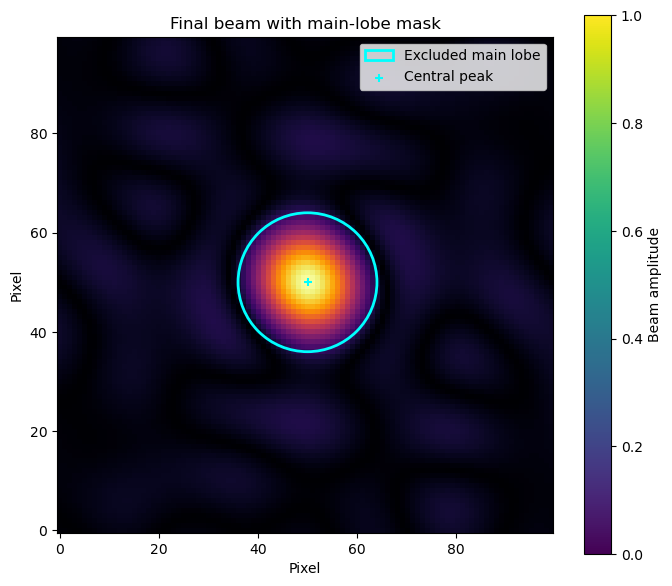

In [33]:
plt.figure(figsize=(8, 7))
plt.imshow(beam_final, origin='lower', cmap='inferno')

# Plot the main-lobe mask boundary
circle = plt.Circle(
    (col_max, row_max),
    radius,
    color='cyan',
    fill=False,
    linewidth=2,
    label='Excluded main lobe')

plt.gca().add_patch(circle)
plt.scatter(col_max, row_max, color='cyan', marker='+', label='Central peak')
plt.colorbar(label='Beam amplitude')
plt.legend()
plt.title('Final beam with main-lobe mask')
plt.xlabel('Pixel')
plt.ylabel('Pixel')
plt.show()

uv samples: (1440, 3)


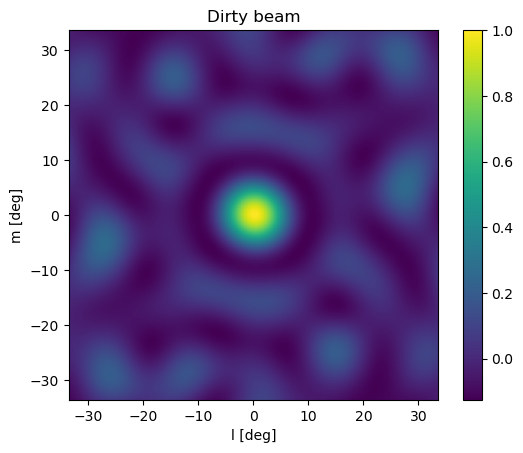

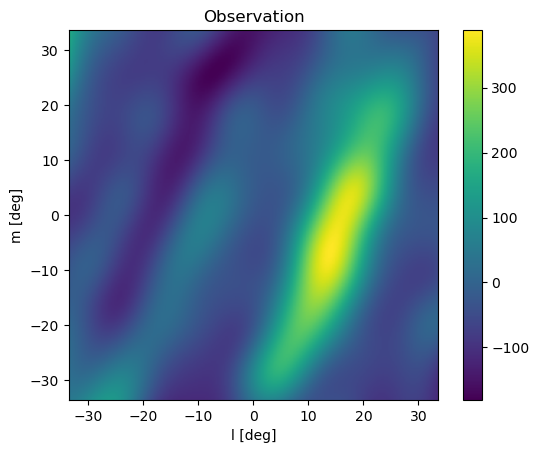

In [34]:
#Observing the sky imaging:
#b_final = b_final = aat.get_baselines(np.array(antenna))
#uv_circ  = antenna_utils.uv_track_multiband(b_final, lat=lat_deg, dec=lat_deg, track_time=track_h, n_times=n_times,f=frequency)

#plt.figure()
#plt.imshow(sky_MW,origin='lower')
#plt.show()

#MW_png = Image.open('HI4PI_20_11.png')
#MW_png = MW_png.resize((256, 256))

#sky_MW = np.array(MW_png)
#sky_MW = np.array(MW_png.convert('L'))

#FOV_single_ant = wavelength/u.m /diam_ant *180/np.pi #   67.202 #deg
#FOV_sky = 256*15.750479/60 #degree
#resolution = FOV_single_ant  /256 *60

#this FOV is for one antenna?, and in deg??
#airy_beam = AiryBeam(r_to_first_null=((1.22*wavelength/(u.m) / diam_ant)*180/np.pi)*u.deg, n_pix=sky_MW.shape[0], fov_deg = FOV_single_ant/2)

#print(airy_beam)
#FOV_single_ant2 = FOV_single_ant *u.deg

#obs,dirty_beam = imaging_utils.simulate_dirty_observation(sky_MW, uv_circ, FOV.value, multi_band=True,beam = airy_beam,freqs=[frequency])
#plot_utils.plot_sky(dirty_beam[0],FOV_single_ant2.value,title='Dirty beam')
#plot_utils.plot_sky(obs[0],(FOV_single_ant2.value,FOV_single_ant2.value), title='Observation')
# uv tracks from BASELINES, with lat/dec in RADIANS
b_final = aat.get_baselines(np.array(antenna))
uv_obs = antenna_utils.uv_track_multiband(
    b_final, lat=lat, dec=lat,
    track_time=track_h, t_0=t_0, n_times=n_times, f=frequency)
print("uv samples:", uv_obs[0].shape)            # (1440, 3)

airy_beam = AiryBeam(r_to_first_null=r_to_first_null.value,
                     n_pix=n_pix, fov_deg=FOV_sky/2)

obs, dirty_beam = imaging_utils.simulate_dirty_observation(
    sky_MW, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])

plot_utils.plot_sky(dirty_beam[0], (FOV_sky, FOV_sky), title='Dirty beam')
plot_utils.plot_sky(obs[0],        (FOV_sky, FOV_sky), title='Observation')

0.9103637378402422
uv samples: (1440, 3)
67.2
max |point-source obs - dirty beam|: 0.011211602339836244
uv samples: (1440, 3)


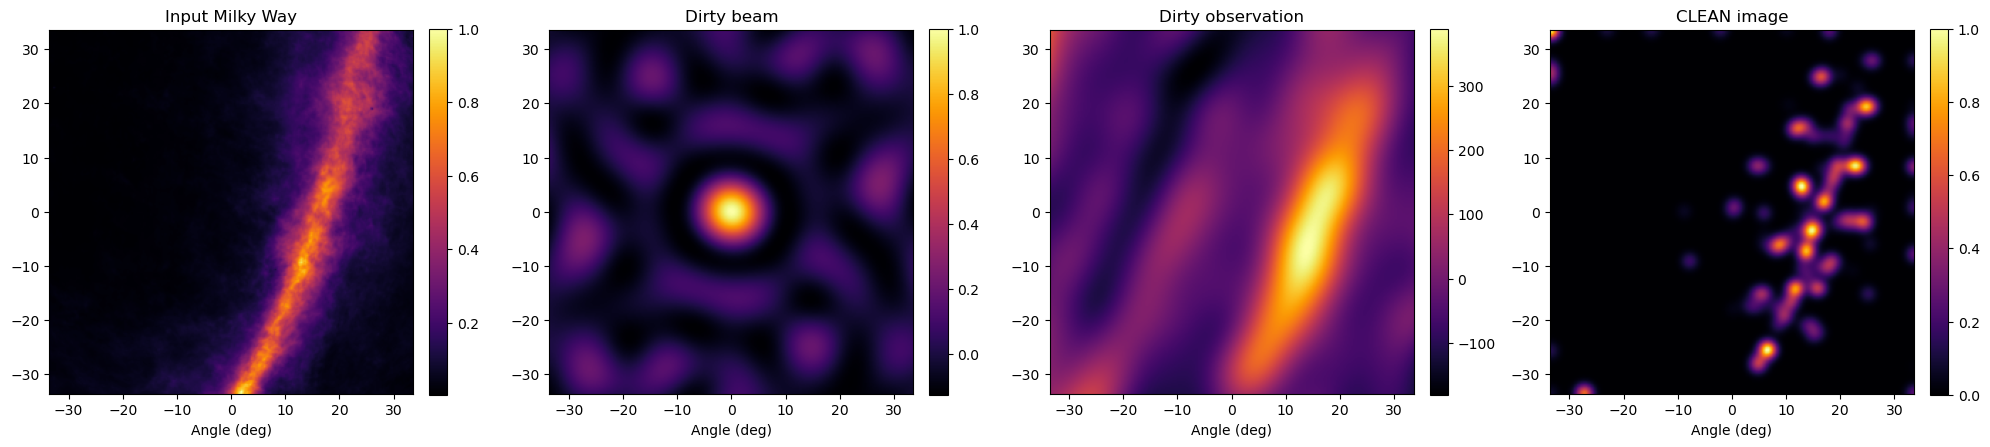

In [35]:
#hihi

import healpy as hp
from astropy.coordinates import Galactic

# Leiden, and the time you used for the zenith pointing
location = EarthLocation.from_geodetic(lon=4.49*u.deg, lat=52.16*u.deg, height=0*u.m)
obstime  = Time('2026-11-20 15:00:00')

hi_map = hp.read_map('HI4PI_MOM0_GAL_1_1024.fits', field=0)

n_pix   = 256
FOV_sky = 67.2                                   # deg, full width (256 * 15.75' / 60)

# Local grid around the zenith: l = East, m = North (row 0 = south)
x = np.linspace(-FOV_sky/2, FOV_sky/2, n_pix)
L, M = np.meshgrid(x, x)
l, m = np.radians(L), np.radians(M)

alt = np.arcsin(np.sqrt(1 - l**2 - m**2))
az  = np.arctan2(l, m)                           # azimuth from north, towards east

altaz = SkyCoord(az=az.ravel()*u.rad, alt=alt.ravel()*u.rad,
                 frame=AltAz(obstime=obstime, location=location))
gal = altaz.transform_to(Galactic())

sky_MW = hp.get_interp_val(hi_map, gal.l.deg, gal.b.deg, lonlat=True).reshape(n_pix, n_pix)
sky_MW = sky_MW / sky_MW.max()                   # float, 0..1

#plt.imshow(sky_MW, origin='lower', extent=[-FOV_sky/2, FOV_sky/2]*2)
#plt.xlabel('l (East) [deg]'); plt.ylabel('m (North) [deg]')
#plt.title('Sky model (local frame)'); plt.colorbar(); plt.show()



#plt.figure()
#plt.imshow(sky_MW,origin='lower')
#plt.show()

print(lat)

uv_obs = antenna_utils.uv_track_multiband(b_final, lat=lat, dec=lat,track_time=track_h, t_0=t_0, n_times=n_times, f=frequency)

print("uv samples:", uv_obs[0].shape)       # expect (72*n_times, 3)

# 2. Float sky and ONE consistent FOV (full width in degrees)

print(FOV_sky) #67 deg

# 3. Primary beam on the same grid
airy_beam = AiryBeam(r_to_first_null=r_to_first_null.value, n_pix=256, fov_deg=FOV_sky/2)

# 4. Observe
obs, dirty_beam = imaging_utils.simulate_dirty_observation(
    sky_MW, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])

#plot_utils.plot_sky(dirty_beam[0], (FOV_sky, FOV_sky), title='Dirty beam')
#plot_utils.plot_sky(obs[0],        (FOV_sky, FOV_sky), title='Observation')

# 5. Sanity test: a point source must reproduce the dirty beam
pt = np.zeros((256, 256)); pt[128, 128] = 1.0
obs_pt, _ = imaging_utils.simulate_dirty_observation(
    pt, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])
print("max |point-source obs - dirty beam|:",
      np.abs(obs_pt[0] / obs_pt[0].max() - dirty_beam[0]).max())

#I_clean, sky_model = clean_hogbom(obs[0], dirty_beam[0], gamma=0.1, max_iter=100000, threshold=1e-3 , clean_beam_size_px=10, res=False)


#I_clean /= np.max(I_clean)
#plot_sky(I_clean, 180)

#Observing the sky imaging:
#uv_circ  = antenna_utils.uv_track_multiband(antenna, lat=lat_deg, dec=lat_deg, track_time=track_h, n_times=n_times,f=frequency)

#plt.figure()
#plt.imshow(sky_MW)
#plt.show()

#MW_png = Image.open('HI4PI_20_11.png')
#MW_png = MW_png.resize((256, 256))

#sky_MW = np.array(MW_png)
#sky_MW = np.array(MW_png.convert('L'))

#print(antenna)


#FOV = 256 * 20 / 60 * u.deg #85, from the image itself

#this FOV is for one antenna?, and in deg??
#airy_beam = AiryBeam(r_to_first_null=((1.22 * wavelength/(u.m) / diam_ant)*180/np.pi)*u.deg, n_pix=sky_MW.shape[0], fov_deg=FOV.value / 2)
#obs,dirty_beam = imaging_utils.simulate_dirty_observation(sky_MW, uv_circ, FOV.value, multi_band=True,beam = airy_beam,freqs=[frequency])
#plot_utils.plot_sky(dirty_beam[0],FOV.value,title='Dirty beam')
#plot_utils.plot_sky(obs[0],(FOV.value,FOV.value), title='Observation')


#plt.figure()
#plt.imshow(sky_double_gauss, origin='lower', extent=[-FOV_sky/2, FOV_sky/2]*2)
#plt.show()

#print(obs[0].shape)
b_final = aat.get_baselines(np.array(antenna))
uv_obs = antenna_utils.uv_track_multiband(
    b_final, lat=lat, dec=lat,
    track_time=track_h, t_0=t_0, n_times=n_times, f=frequency)
print("uv samples:", uv_obs[0].shape)

airy_beam = AiryBeam(r_to_first_null=r_to_first_null.value,
                     n_pix=n_pix, fov_deg=FOV_sky/2)

obs, dirty_beam = imaging_utils.simulate_dirty_observation(
    sky_MW, uv_obs, FOV_sky, multi_band=True, beam=airy_beam, freqs=[frequency])

#plot_utils.plot_sky(dirty_beam[0], (FOV_sky, FOV_sky), title='Dirty beam')
#plot_utils.plot_sky(obs[0],        (FOV_sky, FOV_sky), title='Observation')



# Generate CLEAN image
from argosim.clean import *

I_clean, sky_model = clean_hogbom(
    obs[0],
    dirty_beam[0],
    gamma=0.1,
    max_iter=1000,
    threshold=1e-3,
    clean_beam_size_px=10,
    res=False
)

I_clean /= np.max(I_clean)


# Plot all four images next to each other
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

images = [
    sky_MW,
    dirty_beam[0],
    obs[0],
    I_clean
]

titles = [
    "Input Milky Way",
    "Dirty beam",
    "Dirty observation",
    "CLEAN image"
]

for i in range(4):

    im = ax[i].imshow(
        images[i],
        origin='lower',
        extent=[-FOV_sky/2, FOV_sky/2,
                -FOV_sky/2, FOV_sky/2],
        cmap='inferno'
    )

    ax[i].set_title(titles[i])
    ax[i].set_xlabel("Angle (deg)")
    ax[i].set_aspect('equal')

    plt.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig('9_ant_0.4m_circle_config_result.pdf')
plt.show()

Sky shape: (256, 256)
uv shape: (1440, 3)
FOV: 67.2


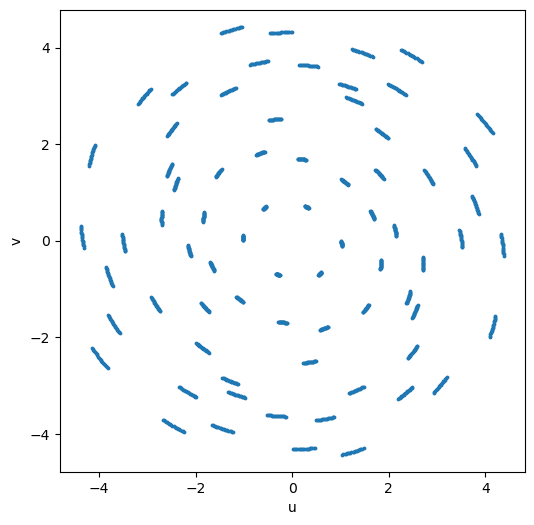

u range: -4.378415144863157 4.378415144863157
v range: -4.4310420342852925 4.4310420342852925


In [36]:
print("Sky shape:", sky_MW.shape)
print("uv shape:", uv_obs[0].shape)
print("FOV:", FOV_sky)

uv_samples = np.array(uv_obs[0])
plt.figure(figsize=(6, 6))
plt.scatter(uv_samples[:, 0], uv_samples[:, 1], s=3)
plt.xlabel("u"); plt.ylabel("v"); plt.axis("equal")
plt.show()

print("u range:", uv_samples[:, 0].min(), uv_samples[:, 0].max())
print("v range:", uv_samples[:, 1].min(), uv_samples[:, 1].max())

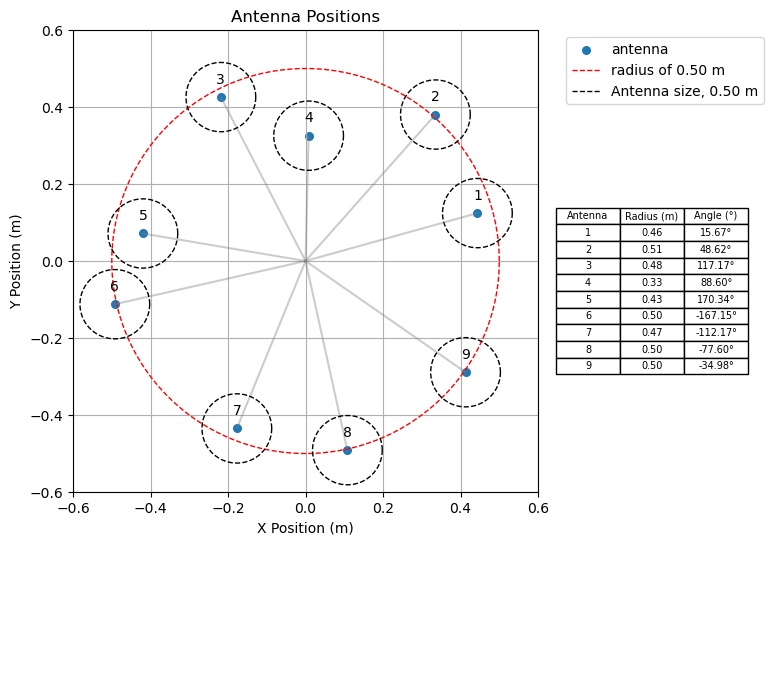

In [ ]:
from matplotlib.widgets import TextBox

radii = np.sqrt(ant_final[:, 0]**2 + ant_final[:, 1]**2)
angles = np.arctan2(ant_final[:, 1], ant_final[:, 0])

theta = np.linspace(0, 2*np.pi, 200)

z = []
for i in range(len(ant_final)):
    z.append(str(i+1))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(ant_final[:, 0], ant_final[:, 1], s=30, label='antenna')
ax.plot(0 + R_MAX*np.cos(theta), 0 + R_MAX*np.sin(theta), 'r--', lw=1, label=f'radius of {R_MAX:.2f} m')

ax.set_xlabel('X Position (m)')
ax.set_ylabel('Y Position (m)')
ax.set_title('Antenna Positions')

ax.plot(ant_final[0, 0] + 0.09*np.cos(theta), ant_final[0, 1] + 0.09*np.sin(theta), '--', color='black', lw=1, label=f'Antenna size, {R_MAX:.2f} m')
ax.plot([ant_final[0, 0], 0.0], [ant_final[0, 1], 0.0], alpha=.4, color='gray')
ax.annotate(z[0], (ant_final[0, 0], ant_final[0, 1]), textcoords="offset points", xytext=(0,10), ha='center')

for i, txt in enumerate(z[1:]):
    ax.plot([ant_final[i+1, 0], 0.0], [ant_final[i+1, 1], 0.0], alpha=.4, color='gray')
    ax.plot(ant_final[i+1, 0] + 0.09*np.cos(theta), ant_final[i+1, 1] + 0.09*np.sin(theta), '--', color='black', lw=1)
    ax.annotate(txt, (ant_final[i+1, 0], ant_final[i+1, 1]), textcoords="offset points", xytext=(0,10), ha='center')

ax.grid(True)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.6, 0.6)
ax.legend(loc='upper right', bbox_to_anchor=(1.5, 1.0))

cell_text = [[str(i+1), f"{radii[i]:.2f}", f"{np.degrees(angles[i]):.2f}°"] for i in range(len(ant_final))]
table_ax = fig.add_axes([0.93, -0.2, 0.32, 0.8])  # [left, bottom, width, height]
table_ax.axis('off')
table = table_ax.table(cellText=cell_text, colLabels=["Antenna", "Radius (m)", "Angle (°)"], loc='upper center', cellLoc='center')

plt.savefig('antenna_positions_with_table.pdf', bbox_inches='tight')
plt.show()


FWHM x: 16.695664566156918 pixels
FWHM y: 15.356722787679097 pixels
FWHM x: 11.21948658845745 degrees
FWHM y: 10.319717713320353 degrees
Position angle: -0.4747754170458346 radians
Major axis peaks: [array([-22.73939394, -13.91515152,  -0.33939394,  13.91515152,
        22.73939394]), array([0.06334913, 0.08032045, 0.99451686, 0.08032045, 0.06334913])]
Minor axis peaks: [array([-30.20606061, -20.7030303 , -12.55757576,   0.33939394,
        12.55757576,  20.7030303 ,  30.20606061]), array([0.04095444, 0.06418085, 0.09964637, 0.99409525, 0.09964637,
       0.06418085, 0.04095444])]


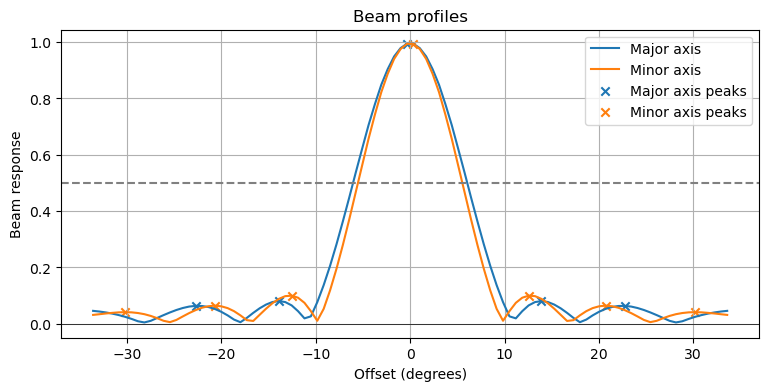

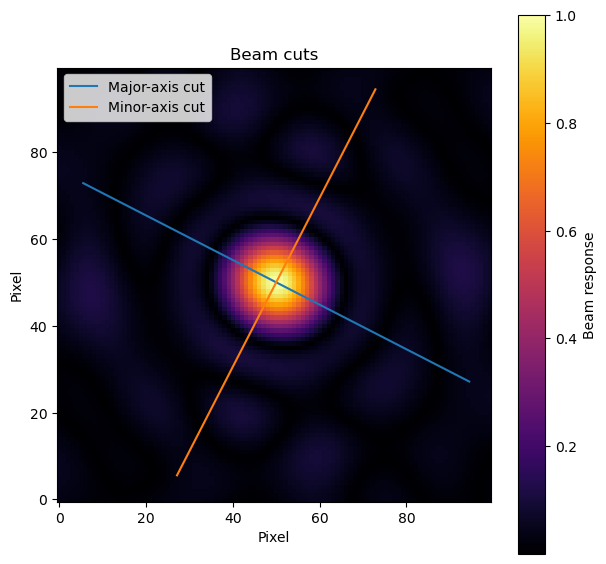

In [128]:
from astropy.modeling import models, fitting
from scipy.ndimage import map_coordinates
from scipy.signal import find_peaks

# -------------------------------
# 1. Fit Gaussian to central beam
# -------------------------------

centre = beam_final.shape[0] // 2
radius = 20  # pixels; adjust to include central lobe only

beam_centre = beam_final[
    centre-radius:centre+radius+1,
    centre-radius:centre+radius+1
]

y, x = np.indices(beam_centre.shape)

gauss_init = models.Gaussian2D(
    amplitude=np.max(beam_centre),
    x_mean=radius,
    y_mean=radius,
    x_stddev=5,
    y_stddev=5
)

fit = fitting.LevMarLSQFitter()
gauss_fit = fit(gauss_init, x, y, beam_centre)

# -------------------------------
# 2. Calculate FWHM
# -------------------------------

factor = 2 * np.sqrt(2 * np.log(2))

fwhm_x = factor * gauss_fit.x_stddev.value
fwhm_y = factor * gauss_fit.y_stddev.value

pixel_scale = FOV_sky / beam_final.shape[1]

print("FWHM x:", fwhm_x, "pixels")
print("FWHM y:", fwhm_y, "pixels")
print("FWHM x:", fwhm_x * pixel_scale, "degrees")
print("FWHM y:", fwhm_y * pixel_scale, "degrees")
print("Position angle:", gauss_fit.theta.value, "radians")

# -------------------------------
# 3. Extract profiles along fitted axes
# -------------------------------

theta = gauss_fit.theta.value

r = np.linspace(-centre, centre, beam_final.shape[0])

# Major axis
x_major = centre + r * np.cos(theta)
y_major = centre + r * np.sin(theta)

# Minor axis
x_minor = centre - r * np.sin(theta)
y_minor = centre + r * np.cos(theta)

profile_major = map_coordinates(
    beam_final, [y_major, x_major], order=1
)

profile_minor = map_coordinates(
    beam_final, [y_minor, x_minor], order=1
)

offset = r * pixel_scale

#Find the peaks
peaks_major_i, _ = find_peaks(profile_major)
peaks_minor_i, _ = find_peaks(profile_minor)

profile_major_peaks = profile_major[peaks_major_i]
profile_minor_peaks = profile_minor[peaks_minor_i]

peaks_major = [offset[peaks_major_i], profile_major_peaks]
peaks_minor = [offset[peaks_minor_i], profile_minor_peaks]

print("Major axis peaks:", peaks_major)
print("Minor axis peaks:", peaks_minor)

# -------------------------------
# 4. Plot 1D profiles
# -------------------------------

plt.figure(figsize=(9, 4))

plt.plot(offset, profile_major, label="Major axis")
plt.plot(offset, profile_minor, label="Minor axis")
plt.axhline(np.max(beam_final) / 2, color='grey', linestyle='--')
plt.axhline(0, color='black', linewidth=0.5)
plt.scatter(peaks_major[0], peaks_major[1], color='C0', marker='x', label='Major axis peaks')
plt.scatter(peaks_minor[0], peaks_minor[1], color='C1', marker='x', label='Minor axis peaks')

plt.xlabel("Offset (degrees)")
plt.ylabel("Beam response")
plt.title("Beam profiles")
plt.legend()
plt.grid()
plt.savefig('1d_plot_beam_ellipse.pdf')
plt.show()



# -------------------------------
# 5. Plot cuts on 2D beam
# -------------------------------

plt.figure(figsize=(7, 7))

plt.imshow(beam_final, origin='lower', cmap='inferno')

plt.plot(x_major, y_major, color='C0', label='Major-axis cut')
plt.plot(x_minor, y_minor, color='C1', label='Minor-axis cut')

plt.xlabel("Pixel")
plt.ylabel("Pixel")
plt.title("Beam cuts")
plt.legend()
plt.colorbar(label="Beam response")
plt.savefig('2d_beam_ellipse_cutouts.pdf')
plt.show()

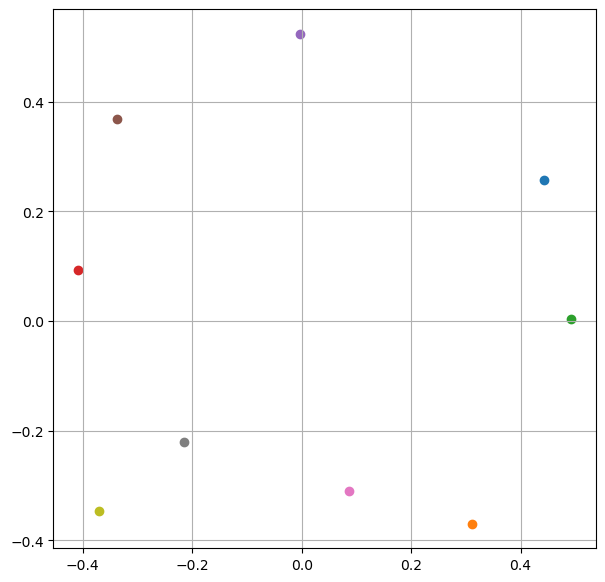

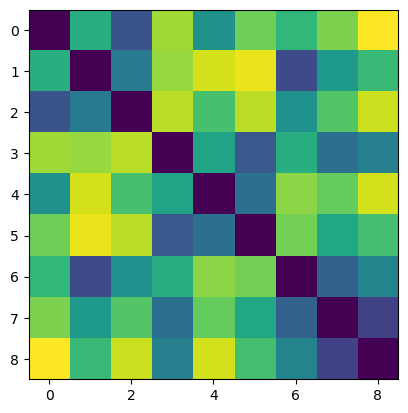

[7 8]
minimal baseline: 0.20004308807400498
[0 8]
max baseline: 1.0126115853515187
11.945713622399404


In [117]:
ant_final = np.array([[1, 0.44351937, 0.25675033],
        [2, 0.31049445, -0.36953188],    
        [3, 0.49270715, 0.00338735],
        [4, -0.40862047, 0.09358719],
        [5, -0.00241969, 0.52380058],
        [6, -0.33720132, 0.36831369],
        [7, 0.08623691, -0.3100637],
        [8, -0.21437422, -0.22048946],
        [9, -0.37034218, -0.34575411]])
R_MAX = 1

fig, ax = plt.subplots(figsize=(7, 7))
for i in range(len(ant_final)):
    ax.scatter(ant_final[i,1], ant_final[i,2])
    ax.annotate(str(ant_final[i,0]), (ant_final[i, 0], ant_final[i, 1]), textcoords="offset points", xytext=(0,10), ha='center')
plt.grid()
plt.show()

x = antenna_final[:, 1]
y = antenna_final[:, 2]
baseline_M = np.zeros((len(antenna_final), len(antenna_final)))
for i in range(len(antenna_final)):
    for j in range(len(antenna_final)):
        baseline_M[i, j] = np.sqrt((x[i] - x[j])**2 + (y[i] - y[j])**2)

plt.imshow(baseline_M)
plt.show()

baseline_M_nodiag = baseline_M + 0.5*np.identity(len(baseline_M))
min1, min2 = np.argwhere(baseline_M_nodiag == np.min(baseline_M_nodiag))
print(min1)
print('minimal baseline:', baseline_M[min1[0],min1[1]])

max1, max2 = np.argwhere(baseline_M_nodiag == np.max(baseline_M_nodiag))
print(max1)
print('max baseline:', baseline_M[max1[0],max1[1]])


resolution = (wavelength/(baseline_M[max1[0],max1[1]]*u.m)) / np.pi *180
print(resolution)

In [ ]:
from itertools import combinations

def split_4_3_2(items):
    items = set(items)
    for a in combinations(sorted(items), 4):
        rest = items - set(a)
        for b in combinations(sorted(rest), 3):
            c = tuple(sorted(rest - set(b)))
            yield a+ b+ c

def normalize(a):
    return np.abs((a - a.min()) / (a.max() - a.min()))

result = np.array(list(split_4_3_2(range(1, 10))))

group4 = result[:, :4]    # shape (1260, 4)
group3 = result[:, 4:7]   # shape (1260, 3)
group2 = result[:, 7:]    # shape (1260, 2)

total_b_score_l = []
div_angle_l = []
for i in range(len(result)):
    combis = result[i]

    group4 = result[i, :4]    # shape (1260, 4)
    group3 = result[i, 4:7]   # shape (1260, 3)
    group2 = result[i, 7:]    # shape (1260, 2)

    group4_combis = combinations(group4, 2)
    b_4 = 0
    theta_4 = np.array([])
    for j, combi in enumerate(group4_combis):
        k, l = combi
        b = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)
        b_4 += b

        theta = np.arctan2(y[k-1] - y[l-1], x[k-1] - x[l-1])
        theta_4 = np.append(theta_4, theta)

    diversity_4 = 1 - np.abs(np.mean(np.exp(2j * theta_4)))
    
    group3_combis = combinations(group3, 2)
    b_3 = 0
    theta_3 = np.array([])
    for j, combi in enumerate(group3_combis):
        k, l = combi
        b = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)
        b_3 += b

        theta = np.arctan2(y[k-1] - y[l-1], x[k-1] - x[l-1])
        theta_3 = np.append(theta_3, theta)
    
    diversity_3 = 1 - np.abs(np.mean(np.exp(2j * theta_3)))
    
    k, l = group2
    b_2 = np.sqrt((x[k-1] - x[l-1])**2 + (y[k-1] - y[l-1])**2)        

    diversity_angle = np.mean((diversity_4, diversity_3))
    div_angle_l.append(diversity_angle)
    total_b_score = b_4 + b_3 + b_2
    total_b_score_l.append(total_b_score)

total_b_score_l = np.asarray(total_b_score_l)
div_angle_l = np.asarray(div_angle_l)

dees = normalize(total_b_score_l)
www = 0.5
score = dees - www * div_angle_l

min_i = np.argwhere(score == min(score))
best_combinations = result[min_i][0,0]

best_group4, best_group3, best_group2 = best_combinations[:4], best_combinations[4:7], best_combinations[7:]
print(best_group4, best_group3, best_group2)



[0.84615501 0.74829197 0.6718998  0.81747846]
[6.14961019 6.14464942 6.28401615 ... 6.03522991 5.73934827 5.94376616]
[0.166586   0.21419766 0.28947356 ... 0.22725479 0.06646558 0.13844882]
[[1 2 3 ... 7 8 9]
 [1 2 3 ... 8 7 9]
 [1 2 3 ... 9 7 8]
 ...
 [6 7 8 ... 5 1 4]
 [6 7 8 ... 5 1 3]
 [6 7 8 ... 5 1 2]] [[35]]
[1 2 3 7] [4 8 9] [5 6]
